# Q1b: Do new public county factors explain the Q1 mismatch?

**Question (Q1, last part):** *"Using publicly available data, investigate various county characteristics that may help explain why there is a mismatch between the Feeding America estimates and the three food shelf metrics."*

**What Q1 already found** (`q1_need_vs_foodshelf_activity.ipynb`, sections 30–37): mismatches line up with **geography, access and the food shelf network** (share of residents whose nearest food shelf is in another county ρ ≈ −0.33; distance; busy regional sites; North Country Food Bank counties lower), **not** with poverty, vehicle access, rural share or SNAP.

**What this notebook adds:** about 27 **new** public factors (`county_factors_2022_2024.csv`, `county_factors_static.csv`, built in `06a_build_county_factors.ipynb`), plus **8 ACS factors from the Census API** added later (`06b_acs_factors.ipynb`: SNAP gap, housing cost burden, foreign-born, non-white, seniors living alone, disability + poverty), grouped into six hypotheses that match the reasons the brief gives for need not turning into food shelf visits:

| Group | Idea | Expected link with the gap |
|---|---|---|
| a. Hardship / economy | unemployment, SAIPE poverty, income, housing cost | **≈ 0** if MMG already captures it (MMG's model uses poverty, unemployment, income) |
| b. Eligibility gaps | food-insecure above the SNAP limit, free/reduced lunch | + (people who can't get SNAP lean on food shelves) |
| c. Physical access | distance, cross-county nearest site, grocery stores, USDA low access, vehicles, broadband | − (barriers lower recorded activity) |
| d. Awareness / stigma / social | limited English, social associations, census response, loneliness, American Indian share, tribal area, Hispanic share | mixed |
| e. Network / supply | sites per 10k, visits per site, food bank region | + for more/bigger sites |
| f. Demographics | 65+, under 18, disability, single parents | − for seniors/disability (mobility, stigma) |

**Outcome = the Q1 "gap"** (Method A): for each year and metric, log2(activity) is regressed on log2(MMG food-insecure people); the gap is the county's distance from that line in log2 units (+1 = 2× the expected activity, −1 = half). We use the **2022–2024 average gap per metric** (visits, pounds, individuals) and their average ("all metrics"). We **reuse the saved Q1 tables** and only re-derive a few numbers to confirm they match.

Section 16 adds a small **children** version of Q1 (child food insecurity vs. children served).

**Data rule:** only 2022–2024 food shelf data and public factors with vintages up to 2024 are used. Nothing dated August 2026 or later.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "Data" / "processed"
OUT = ROOT / "outputs" / "q1b"
OUT.mkdir(parents=True, exist_ok=True)

# Same look and metric colours as the Q1 notebook
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b2b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
})
METRICS = ["visits", "pounds", "individuals"]
OUTCOMES = {"mean_gap_all": "All metrics", "visits_mean_gap": "Visits",
            "pounds_mean_gap": "Pounds", "individuals_mean_gap": "Individuals"}
COLOR = {"All metrics": "#3d3d3a", "Visits": "#2a78d6", "Pounds": "#eb6834", "Individuals": "#1baf7a"}
GROUP_COLOR = {"lower than expected": "#e34948", "no persistent mismatch": "#b5b4ac", "higher than expected": "#2a78d6"}
ALPHA = 0.05

## 1. Load the saved Q1 tables and the new factors

- `q1_county_profiles.csv`: one row per county, with the three metric gaps, the overall gap, the mismatch group and Q1's access/network characteristics.
- `q1_county_year_mismatch.csv`: county × year gaps (used for the change-over-time check).
- `county_factors_2022_2024.csv` (county × year) and `county_factors_static.csv` (one vintage).

Wilkin has no food shelf, so it is not scored: **86 counties**.

In [2]:
prof = pd.read_csv(PROCESSED / "q1_county_profiles.csv", dtype={"fips": str})
cy   = pd.read_csv(PROCESSED / "q1_county_year_mismatch.csv", dtype={"fips": str})
fy   = pd.read_csv(PROCESSED / "county_factors_2022_2024.csv", dtype={"fips": str})
fs_static = pd.read_csv(PROCESSED / "county_factors_static.csv", dtype={"fips": str})

# Hard rule: nothing dated August 2026 or later. These files only cover 2022-2024 (or older vintages).
assert fy["year"].between(2022, 2024).all() and cy["year"].between(2022, 2024).all()

scored = prof[prof["direction"] != "not scored (no food shelf in data)"].copy()
print("Q1 profiles:", prof.shape, "| scored counties:", len(scored), "| county-years:", len(cy))
print(scored["direction"].value_counts().to_string())

Q1 profiles: (87, 42) | scored counties: 86 | county-years: 261
direction
no persistent mismatch    60
higher than expected      16
lower than expected       10


## 2. Can we reproduce Q1's numbers?

We rebuild the Method A gaps from the cleaned food shelf and MMG files and compare them with the saved tables.

In [3]:
# Rebuild Method A from the cleaned inputs (same steps as Q1 sections 5 and 17)
fs = pd.read_csv(PROCESSED / "foodshelf_county_month.csv", dtype={"fips": str}, parse_dates=["month"])
mmg = pd.read_csv(PROCESSED / "mmg_mn_county_2022_2024.csv", dtype={"fips": str})
fs = fs[fs["month"].dt.year.between(2022, 2024)].assign(year=lambda d: d["month"].dt.year)
fs_year = fs.groupby(["fips", "year"])[METRICS].sum(min_count=1).reset_index()
re = mmg[["fips", "year", "fi_persons"]].merge(fs_year, on=["fips", "year"]).dropna(subset=["visits"])

slopes = {}
for year, g in re.groupby("year"):
    x = np.log2(g["fi_persons"])
    for m in METRICS:
        y = np.log2(g[m])
        b, a = np.polyfit(x, y, 1)
        re.loc[g.index, f"{m}_gap"] = y - (a + b * x)
        slopes[(year, m)] = b

re_county = re.groupby("fips")[[f"{m}_gap" for m in METRICS]].mean()
re_county["re_all"] = re_county.mean(axis=1)
chk = scored.set_index("fips")[["county", "visits_mean_gap", "pounds_mean_gap", "individuals_mean_gap", "mean_gap_all"]].join(re_county)

print(f"Visits slope 2022: {slopes[(2022, 'visits')]:.2f} (Q1 section 17: 1.20)")
print(f"Pounds slope 2023: {slopes[(2023, 'pounds')]:.2f} (Q1 section 17: 1.15)")
nic = chk[chk["county"] == "Nicollet"].iloc[0]
print(f"Nicollet mean gap, all metrics: recomputed {nic['re_all']:.2f} vs saved {nic['mean_gap_all']:.2f} (Q1 section 21: -1.76)")
for m in METRICS:
    print(f"max |recomputed - saved| {m} mean gap: {(chk[f'{m}_gap'] - chk[f'{m}_mean_gap']).abs().max():.1e}")
print(f"max |recomputed - saved| mean_gap_all: {(chk['re_all'] - chk['mean_gap_all']).abs().max():.1e}")

Visits slope 2022: 1.20 (Q1 section 17: 1.20)
Pounds slope 2023: 1.15 (Q1 section 17: 1.15)
Nicollet mean gap, all metrics: recomputed -1.76 vs saved -1.76 (Q1 section 21: -1.76)
max |recomputed - saved| visits mean gap: 3.6e-15
max |recomputed - saved| pounds mean gap: 3.7e-15
max |recomputed - saved| individuals mean gap: 1.3e-15
max |recomputed - saved| mean_gap_all: 1.5e-15


**Yes.** The slopes (1.20, 1.15) and Nicollet's overall gap (−1.76) match Q1 sections 17 and 21, and every county's mean gap matches the saved table to floating-point precision. So from here on we use the saved tables.

## 3. Build one factor table (one row per county)

- **Year-varying factors** (unemployment, SAIPE poverty and income) are averaged over 2022–2024, the same years as the gaps.
- **Grocery stores per 10k** uses County Business Patterns 2022–2023 (2024 isn't released). CBP hides counts below 3, so 17 small counties are blank. Main version: give them the midpoint (1 store); the robustness section drops them instead.
- **Static factors** (SVI 2022, USDA food access, County Health Rankings 2025) are one vintage, so they describe the period, not a single year.

In [4]:
# Time-varying factors -> one value per county (2022-2024 average; ranks barely move between years)
tv = (fy.groupby("fips")[["unemployment_rate", "saipe_poverty_rate", "saipe_child_poverty_rate", "median_hh_income"]]
        .mean())

# Grocery stores: CBP 2022-2023 only (2024 not released). Counties with 0-2 stores are suppressed in CBP.
# Main version: give suppressed county-years the midpoint (1 store); robustness check later drops them.
g = fy[fy["year"].isin([2022, 2023])].copy()
supp = g["grocery_count_lt3"].astype(str).str.upper().eq("TRUE")
g["n_groc_imp"] = np.where(supp, 1.0, g["n_grocery_stores"])
g["groc_imp_per_10k"] = g["n_groc_imp"] / g["pop_pep"] * 1e4
tv["grocery_stores_per_10k"] = g.groupby("fips")["groc_imp_per_10k"].mean()
tv["grocery_suppressed"] = g.groupby("fips")["grocery_count_lt3"].apply(lambda s: s.astype(str).str.upper().eq("TRUE").any())
tv["grocery_stores_per_10k_reported"] = g.groupby("fips")["grocery_stores_per_10k"].mean()

# ACS 5-year factors from 06b (Census API): average of the 2018-22, 2019-23 and 2020-24 windows
ACS_Q1 = ["pct_hh_cost_burdened_30", "pct_hh_severe_burden_50", "pct_hh_snap", "pct_poverty_hh_no_snap",
          "pct_foreign_born", "pct_nonwhite", "pct_65plus_living_alone", "pct_disabled_in_poverty"]
tv = tv.join(fy.groupby("fips")[ACS_Q1].mean())

d = scored.merge(tv.reset_index(), on="fips", how="left", validate="one_to_one")
d = d.merge(fs_static.drop(columns="county"), on="fips", how="left", validate="one_to_one")
d["log2_sites_per_10k"] = np.log2(d["sites_per_10k"])
print("Merged:", d.shape, "| suppressed grocery counties:", int(d["grocery_suppressed"].sum()))

Merged: (86, 108) | suppressed grocery counties: 17


## 4. The candidate factors, by hypothesis group

`is_new` = not used in Q1. Q1's own factors are kept as reference points so new and old can be compared on the same footing.

**Left out on purpose:**
- **CHR food environment index**: it is built partly from Map the Meal Gap food insecurity, which is the thing we're comparing against, so it would be circular.
- **SVI percentiles**: composites of factors already in the list.

In [5]:
# (column, label, group, new?, hypothesised sign of the link with the gap: + = more activity than MMG predicts)
F = [
 # (a) hardship / economy
 ("unemployment_rate",              "Unemployment rate (BLS)",            "a. Hardship/economy", True,  "+/0"),
 ("saipe_poverty_rate",             "Poverty rate (SAIPE)",               "a. Hardship/economy", True,  "+/0"),
 ("saipe_child_poverty_rate",       "Child poverty rate (SAIPE)",         "a. Hardship/economy", True,  "+/0"),
 ("median_hh_income",               "Median household income (SAIPE)",    "a. Hardship/economy", True,  "-/0"),
 ("pct_below_150_poverty",          "% below 150% poverty (SVI)",         "a. Hardship/economy", True,  "+/0"),
 ("pct_housing_cost_burden_lowinc", "% low-income housing cost burden",   "a. Hardship/economy", True,  "+"),
 ("chr_income_inequality_ratio",    "Income inequality (80/20 ratio)",    "a. Hardship/economy", True,  "+"),
 ("pct_uninsured",                  "% uninsured",                        "a. Hardship/economy", True,  "+"),
 ("poverty_rate",                   "Poverty rate (ACS, Q1)",             "a. Hardship/economy", False, "+/0"),
 # (b) eligibility gaps
 ("pct_fi_above_snap_threshold",    "% food-insecure above SNAP limit",   "b. Eligibility gaps", False, "+"),
 ("chr_pct_children_frl_eligible",  "% children free/reduced lunch",      "b. Eligibility gaps", True,  "?"),
 ("snap_rate",                      "SNAP participation % (Q1, n=74)",    "b. Eligibility gaps", False, "?"),
 # (c) physical access
 ("mean_dist_mi",                   "Avg miles to nearest food shelf",    "c. Physical access",  False, "-"),
 ("pct_over_10mi",                  "% residents >10 mi from food shelf", "c. Physical access",  False, "-"),
 ("pct_nearest_other_county",       "% nearest food shelf in other county","c. Physical access", False, "-"),
 ("no_vehicle_rate",                "% households no vehicle",            "c. Physical access",  False, "-"),
 ("pct_rural_2020",                 "Rural share % (2020)",               "c. Physical access",  False, "-"),
 ("grocery_stores_per_10k",         "Grocery stores per 10k (CBP)",       "c. Physical access",  True,  "?"),
 ("fara_pct_low_access_1_10",       "% low access to supermarket (USDA)", "c. Physical access",  True,  "-"),
 ("fara_pct_lowinc_low_access_1_10","% low-income & low access (USDA)",   "c. Physical access",  True,  "-"),
 ("fara_pct_hh_novehicle_low_access","% no-car & low access hh (USDA)",   "c. Physical access",  True,  "-"),
 ("chr_pct_broadband",              "% households with broadband",        "c. Physical access",  True,  "+"),
 ("pct_no_internet",                "% households no internet",           "c. Physical access",  True,  "-"),
 ("chr_pct_long_commute_alone",     "% long solo commute (>30 min)",      "c. Physical access",  True,  "-"),
 # (d) awareness / stigma / social proxies
 ("pct_limited_english",            "% limited English",                  "d. Awareness/stigma/social", True, "-"),
 ("chr_social_associations_per_10k","Social associations per 10k",        "d. Awareness/stigma/social", True, "+"),
 ("chr_pct_census_participation",   "Census 2020 self-response %",        "d. Awareness/stigma/social", True, "+"),
 ("chr_pct_loneliness",             "% adults lonely",                    "d. Awareness/stigma/social", True, "-"),
 ("pct_aian",                       "% American Indian",                  "d. Awareness/stigma/social", True, "-"),
 ("pct_pop_tribal_area_approx",     "% living in tribal area (approx.)",  "d. Awareness/stigma/social", True, "-"),
 ("pct_hispanic",                   "% Hispanic",                         "d. Awareness/stigma/social", True, "-"),
 # (e) network / supply
 ("sites_per_10k",                  "Food shelf sites per 10k",           "e. Network/supply",   False, "+"),
 ("visits_per_site_month",          "Visits per site-month (circular)",   "e. Network/supply",   False, "+"),
 ("pct_visits_supershelf",          "% visits at SuperShelf sites",       "e. Network/supply",   False, "?"),
 # (f) demographics
 ("pct_age_65plus",                 "% age 65+",                          "f. Demographics",     True,  "-"),
 ("pct_age_17under",                "% under 18",                         "f. Demographics",     True,  "+"),
 ("pct_disability",                 "% with a disability",                "f. Demographics",     True,  "-"),
 ("pct_single_parent_hh",           "% single-parent households",         "f. Demographics",     True,  "+"),
 # ---- ACS 5-year via Census API (06b_acs_factors.ipynb), added after the first run
 ("pct_hh_cost_burdened_30",        "% households cost-burdened ≥30% (ACS)",  "a. Hardship/economy", True, "+"),
 ("pct_hh_severe_burden_50",        "% households severely burdened ≥50% (ACS)", "a. Hardship/economy", True, "+"),
 ("pct_hh_snap",                    "% households on SNAP (ACS)",          "b. Eligibility gaps", True,  "?"),
 ("pct_poverty_hh_no_snap",         "SNAP gap: poverty hh without SNAP (ACS)", "b. Eligibility gaps", True, "-"),
 ("pct_foreign_born",               "% foreign-born (ACS)",                "d. Awareness/stigma/social", True, "-"),
 ("pct_nonwhite",                   "% non-white or Hispanic (ACS)",       "d. Awareness/stigma/social", True, "?"),
 ("pct_65plus_living_alone",        "% of 65+ living alone (ACS)",         "f. Demographics",     True,  "-"),
 ("pct_disabled_in_poverty",        "% of disabled people in poverty (ACS)", "f. Demographics",   True,  "-"),
]
FAC = pd.DataFrame(F, columns=["factor", "label", "group", "is_new", "hyp_sign"]).set_index("factor")
FAC["batch"] = np.where(FAC.index.isin(ACS_Q1), "06b ACS (Census API)", np.where(FAC["is_new"], "06a", "Q1"))
# keep each group's rows together (ACS rows go to the end of their hypothesis group)
FAC = FAC.iloc[np.argsort(FAC["group"].values, kind="stable")]
assert FAC.index.isin(d.columns).all(), FAC.index[~FAC.index.isin(d.columns)]
print(f"{len(FAC)} continuous factors ({FAC['is_new'].sum()} new: {(FAC['batch'] == '06a').sum()} from 06a + "
      f"{(FAC['batch'] != 'Q1').sum() - (FAC['batch'] == '06a').sum()} ACS from 06b; {(~FAC['is_new']).sum()} already in Q1) "
      f"+ food bank region (categorical)")
FAC.groupby("group").agg(n=("is_new", "size"), new=("is_new", "sum"), acs=("batch", lambda s: (s != "Q1").sum() - (s == "06a").sum()))

46 continuous factors (35 new: 27 from 06a + 8 ACS from 06b; 11 already in Q1) + food bank region (categorical)


,n,new,acs
group,,,
a. Hardship/economy,11,10,2
b. Eligibility gaps,5,3,2
c. Physical access,12,7,0
d. Awareness/stigma/social,9,9,2
e. Network/supply,3,0,0
f. Demographics,6,6,2


46 continuous factors (35 new: 27 from `06a` + 8 ACS factors from `06b`) plus the food bank region. **Testing 46 factors × 4 outcomes = 184 correlations (+4 food bank tests = 188).** At p < 0.05, about **9 would look "significant" by pure chance** even if nothing were real. That is why we correct for multiple testing below.

**More tests than the first version (156 → 188).** Adding the 8 ACS factors makes the FDR correction slightly stricter for every test. The saved table keeps both q-values: `q_fdr` (all 188 tests) and `q_fdr_before_acs` (the original 156-test family, blank for ACS rows), so the first version's numbers can still be checked.

Two ACS measures are **not** tested here because they duplicate SVI factors already in the list: ACS `pct_aian_alone` (r = 0.999 with SVI `pct_aian`) and `pct_hispanic_acs` (r = 1.00 with SVI `pct_hispanic`).

## 5. One factor at a time: Spearman correlation with each gap

- **Spearman ρ** (rank correlation) so one extreme county can't create a pattern.
- **Multiple-testing correction (Benjamini–Hochberg FDR).** The *q-value* is the p-value adjusted for how many tests we ran. **q < 0.05 is our bar for "survives correction".** Main family = all 188 tests together. We also show a looser version, FDR within each metric (47 tests each).
- **Food bank region** is a category, so it gets a Kruskal–Wallis test (do the gaps differ between food banks?) instead of a ρ.

In [6]:
rows = []
for f, meta in FAC.iterrows():
    for oc, olab in OUTCOMES.items():
        sub = d[[f, oc]].dropna()
        rho, p = stats.spearmanr(sub[f], sub[oc])
        rows.append({"factor": f, "label": meta["label"], "group": meta["group"], "is_new": meta["is_new"],
                     "metric": olab, "test": "spearman", "n": len(sub), "rho": rho, "p": p})
# Food bank region: categorical, so Kruskal-Wallis across the food banks (no rho)
for oc, olab in OUTCOMES.items():
    sub = d[["main_food_bank", oc]].dropna()
    p = stats.kruskal(*[g[oc] for _, g in sub.groupby("main_food_bank")]).pvalue
    rows.append({"factor": "main_food_bank", "label": "Main food bank (Kruskal-Wallis)", "group": "e. Network/supply",
                 "is_new": False, "metric": olab, "test": "kruskal", "n": len(sub), "rho": np.nan, "p": p})
tests = pd.DataFrame(rows)

# Benjamini-Hochberg FDR across ALL tests in one family (39 factors x 4 outcomes)
tests["q_fdr"] = multipletests(tests["p"], method="fdr_bh")[1]
# Secondary: FDR within each outcome (39 tests each), less strict
tests["q_fdr_within_metric"] = tests.groupby("metric")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
tests["direction"] = np.select([tests["rho"] > 0, tests["rho"] < 0],
                               ["higher factor -> more activity than expected", "higher factor -> less activity than expected"],
                               default="n/a (categorical)")
tests["survives_fdr"] = tests["q_fdr"] < ALPHA
tests["batch"] = tests["factor"].map(FAC["batch"]).fillna("Q1")
# The original (pre-ACS) family of 156 tests, kept so the first version's q-values can be checked
pre = tests["batch"] != "06b ACS (Census API)"
tests.loc[pre, "q_fdr_before_acs"] = multipletests(tests.loc[pre, "p"], method="fdr_bh")[1]

n_tests = len(tests)
print(f"{n_tests} tests | p < 0.05: {(tests['p'] < ALPHA).sum()} (about {ALPHA * n_tests:.0f} expected by chance alone) "
      f"| q < 0.05 (all-tests FDR): {tests['survives_fdr'].sum()} | q < 0.05 (within-metric FDR): {(tests['q_fdr_within_metric'] < ALPHA).sum()}")
print(f"Among NEW factors only: p < 0.05: {((tests['p'] < ALPHA) & tests['is_new']).sum()} of {tests['is_new'].sum()} tests; "
      f"q < 0.05: {(tests['survives_fdr'] & tests['is_new']).sum()}")
acs_t = tests["batch"] == "06b ACS (Census API)"
print(f"ACS factors only: {acs_t.sum()} tests | p < 0.05: {((tests['p'] < ALPHA) & acs_t).sum()} | q < 0.05: {(tests['survives_fdr'] & acs_t).sum()} "
      f"| smallest q: {tests.loc[acs_t, 'q_fdr'].min():.2f}")

wide = tests.pivot_table(index=["group", "label"], columns="metric", values="rho", sort=False)[list(OUTCOMES.values())]
wide["p (all)"] = tests[tests["metric"] == "All metrics"].set_index(["group", "label"])["p"]
wide["q (all)"] = tests[tests["metric"] == "All metrics"].set_index(["group", "label"])["q_fdr"]
wide.round(3)

188 tests | p < 0.05: 23 (about 9 expected by chance alone) | q < 0.05 (all-tests FDR): 0 | q < 0.05 (within-metric FDR): 2
Among NEW factors only: p < 0.05: 2 of 140 tests; q < 0.05: 0
ACS factors only: 32 tests | p < 0.05: 1 | q < 0.05: 0 | smallest q: 0.31


metric                                                                All metrics  Visits  Pounds  Individuals  p (all)  q (all)
group                      label                                                                                                
a. Hardship/economy        Unemployment rate (BLS)                          0.068   0.062   0.096        0.026    0.534    0.817
                           Poverty rate (SAIPE)                            -0.108  -0.098  -0.133       -0.106    0.320    0.769
                           Child poverty rate (SAIPE)                       0.001  -0.006  -0.039        0.014    0.991    0.991
                           Median household income (SAIPE)                  0.137   0.114   0.161        0.129    0.209    0.750
                           % below 150% poverty (SVI)                      -0.197  -0.173  -0.246       -0.171    0.070    0.547
                           % low-income housing cost burden                -0.171  -0.122  -0.180       -0.185    0.116    0.637
                           Income inequality (80/20 ratio)                 -0.098  -0.074  -0.131       -0.095    0.368    0.769
                           % uninsured                                     -0.048  -0.005  -0.141       -0.010    0.659    0.834
                           Poverty rate (ACS, Q1)                          -0.162  -0.157  -0.188       -0.141    0.137    0.667
                           % households cost-burdened ≥30% (ACS)           -0.084  -0.058  -0.045       -0.116    0.440    0.769
                           % households severely burdened ≥50% (ACS)       -0.121  -0.083  -0.125       -0.120    0.267    0.769
b. Eligibility gaps        % food-insecure above SNAP limit                 0.122   0.101   0.176        0.107    0.263    0.769
                           % children free/reduced lunch                    0.059   0.053  -0.005        0.083    0.589    0.817
                           SNAP participation % (Q1, n=74)                 -0.058  -0.068  -0.103       -0.049    0.623    0.820
                           % households on SNAP (ACS)                      -0.088  -0.088  -0.147       -0.062    0.418    0.769
                           SNAP gap: poverty hh without SNAP (ACS)         -0.052  -0.034  -0.006       -0.067    0.638    0.827
c. Physical access         Avg miles to nearest food shelf                 -0.238  -0.238  -0.170       -0.248    0.027    0.288
                           % residents >10 mi from food shelf              -0.273  -0.254  -0.227       -0.270    0.011    0.267
                           % nearest food shelf in other county            -0.334  -0.327  -0.285       -0.332    0.002    0.098
                           % households no vehicle                         -0.092  -0.095  -0.117       -0.075    0.399    0.769
                           Rural share % (2020)                             0.061   0.068   0.057        0.042    0.574    0.817
                           Grocery stores per 10k (CBP)                    -0.022  -0.023  -0.057        0.004    0.843    0.932
                           % low access to supermarket (USDA)              -0.030  -0.062   0.040       -0.045    0.785    0.911
                           % low-income & low access (USDA)                -0.081  -0.109  -0.016       -0.089    0.460    0.779
                           % no-car & low access hh (USDA)                 -0.127  -0.138  -0.060       -0.139    0.244    0.759
                           % households with broadband                      0.089   0.089   0.099        0.087    0.416    0.769
                           % households no internet                        -0.127  -0.113  -0.136       -0.128    0.244    0.759
                           % long solo commute (>30 min)                    0.117   0.165   0.056        0.110    0.284    0.769
d. Awareness/stigma/social % limited English                                0.086   0.086   0.009        0.156    0.433    0.769
 

In [7]:
# Everything with p < 0.05 on at least one outcome, sorted by q
tests[tests["p"] < ALPHA].sort_values("q_fdr")[["label", "group", "is_new", "metric", "n", "rho", "p", "q_fdr", "q_fdr_within_metric"]].round(3)

,label,group,is_new,metric,n,rho,p,q_fdr,q_fdr_within_metric
75,% nearest food shelf in other county,c. Physical access,False,Individuals,86,-0.332,0.002,0.098,0.084
185,Main food bank (Kruskal-Wallis),e. Network/supply,False,Visits,86,NaN,0.002,0.098,0.049
72,% nearest food shelf in other county,c. Physical access,False,All metrics,86,-0.334,0.002,0.098,0.079
73,% nearest food shelf in other county,c. Physical access,False,Visits,86,-0.327,0.002,0.098,0.049
184,Main food bank (Kruskal-Wallis),e. Network/supply,False,All metrics,86,NaN,0.014,0.267,0.215
155,Visits per site-month (circular),e. Network/supply,False,Individuals,86,0.245,0.023,0.267,0.214
153,Visits per site-month (circular),e. Network/supply,False,Visits,86,0.250,0.020,0.267,0.189
149,Food shelf sites per 10k,e. Network/supply,False,Visits,86,0.257,0.017,0.267,0.189
148,Food shelf sites per 10k,e. Network/supply,False,All metrics,86,0.251,0.020,0.267,0.232
74,% nearest food shelf in other county,c. Physical access,False,Pounds,86,-0.285,0.008,0.267,0.364


In [8]:
# Save the test table (the 188 original tests). Existing values must not change: compare with the saved file first.
save_cols = ["factor", "label", "group", "is_new", "metric", "test", "n", "rho", "p", "q_fdr", "q_fdr_within_metric",
             "survives_fdr", "direction", "batch", "q_fdr_before_acs"]   # last two added with the ACS factors
TESTS_CSV = PROCESSED / "q1b_factor_tests.csv"

def assert_unchanged(new, path=TESTS_CSV, n=None):
    """The first n rows of the saved file (original columns) must equal `new` (to float precision)."""
    if not path.exists():
        return
    old = pd.read_csv(path)
    n = len(new) if n is None else n
    o, w = old.iloc[:n][save_cols].reset_index(drop=True), new.iloc[:n][save_cols].reset_index(drop=True)
    for c in save_cols:
        if pd.api.types.is_numeric_dtype(o[c]) and c not in ("is_new", "survives_fdr"):
            assert np.allclose(o[c].astype(float), w[c].astype(float), equal_nan=True, rtol=0, atol=1e-9), c
        else:
            assert (o[c].astype(str) == w[c].astype(str)).all(), c

assert_unchanged(tests[save_cols])
if not TESTS_CSV.exists() or len(pd.read_csv(TESTS_CSV)) < len(tests):
    tests[save_cols].to_csv(TESTS_CSV, index=False)      # first run only; section 8c appends the 06c rows
print("Original", len(tests), "test rows checked against", TESTS_CSV.name, "(unchanged)")

Original 188 test rows checked against q1b_factor_tests.csv (unchanged)


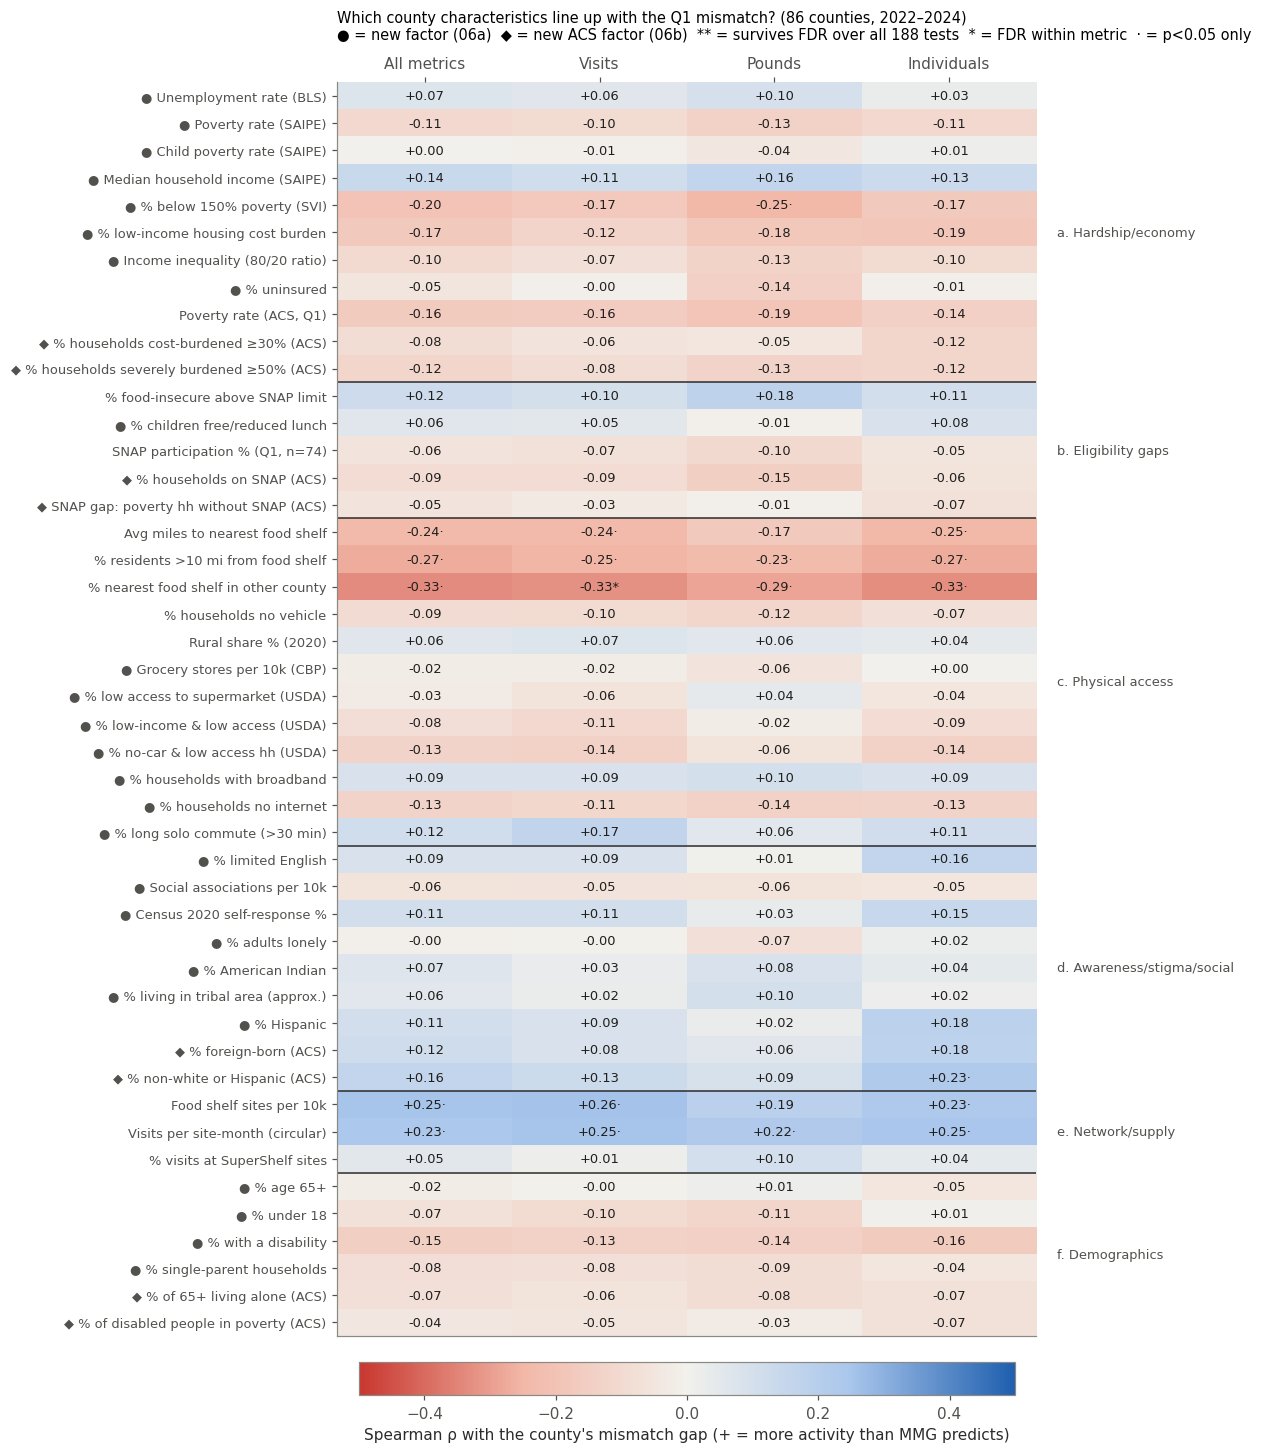

In [9]:
# Heatmap: factor x outcome Spearman rho; ** = survives all-tests FDR (q<0.05), * = within-metric FDR, . = raw p<0.05
DIV = LinearSegmentedColormap.from_list("div", ["#c8372f", "#f2b8a8", "#f2f1ec", "#a9c6ec", "#1f5fae"])
hm = tests[tests["test"] == "spearman"].copy()
order = FAC.index.tolist()
R = hm.pivot(index="factor", columns="metric", values="rho").loc[order, list(OUTCOMES.values())]
Q = hm.pivot(index="factor", columns="metric", values="q_fdr").loc[order, list(OUTCOMES.values())]
QW = hm.pivot(index="factor", columns="metric", values="q_fdr_within_metric").loc[order, list(OUTCOMES.values())]
P = hm.pivot(index="factor", columns="metric", values="p").loc[order, list(OUTCOMES.values())]

fig, ax = plt.subplots(figsize=(8.2, 15.5))
im = ax.imshow(R.values, cmap=DIV, vmin=-0.5, vmax=0.5, aspect="auto")
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        mark = "**" if Q.iat[i, j] < ALPHA else ("*" if QW.iat[i, j] < ALPHA else ("·" if P.iat[i, j] < ALPHA else ""))
        ax.text(j, i, f"{R.iat[i, j]:+.2f}{mark}", ha="center", va="center", fontsize=8.5, color="#1f1f1d")
ylabels = [("◆ " if FAC.loc[f, "batch"].startswith("06b") else ("● " if FAC.loc[f, "is_new"] else "")) + FAC.loc[f, "label"] for f in order]
ax.set_yticks(range(len(order))); ax.set_yticklabels(ylabels, fontsize=8.5)
ax.set_xticks(range(4)); ax.set_xticklabels(list(OUTCOMES.values())); ax.xaxis.tick_top()
ax.grid(False)
# group separators and names
grp = FAC["group"].tolist()
for i in range(1, len(grp)):
    if grp[i] != grp[i - 1]:
        ax.axhline(i - 0.5, color="#2b2b2b", lw=1)
for gname in dict.fromkeys(grp):
    idx = [i for i, x in enumerate(grp) if x == gname]
    ax.text(3.62, np.mean(idx), gname, va="center", ha="left", fontsize=8.5, color="#52514e")
cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.025, pad=0.02)
cb.set_label("Spearman ρ with the county's mismatch gap (+ = more activity than MMG predicts)")
ax.set_title(f"Which county characteristics line up with the Q1 mismatch? (86 counties, 2022–2024)\n"
             f"● = new factor (06a)  ◆ = new ACS factor (06b)  ** = survives FDR over all {n_tests} tests  * = FDR within metric  · = p<0.05 only",
             fontsize=9.5, loc="left", pad=28)
fig.savefig(OUT / "q1b_factor_heatmap.png")
plt.show()

**What the table and heatmap show**

- **No factor survives the main FDR correction** (all q ≥ 0.10 over 188 tests). 23 tests have p < 0.05, against about 9 expected by chance, so there is *some* signal, but it's concentrated in Q1's existing factors.
- **The strongest are still Q1's access and network factors.** Top: share of residents whose nearest food shelf is in another county (ρ ≈ −0.33, p ≈ 0.002, q ≈ 0.10; it was q ≈ 0.08 over the first 156 tests, see `q_fdr_before_acs`), then % over 10 miles (−0.27), sites per 10k (+0.25) and average distance (−0.24). With the looser **within-metric FDR**, the cross-county share (visits, q ≈ 0.049) and the food bank region (visits, q ≈ 0.049) still pass.
- **The new factors show almost nothing.** Only **2 of 140** new-factor tests reach even p < 0.05 (fewer than the ~7 chance alone would produce): % below 150% of poverty vs. the pounds gap (ρ ≈ −0.25) and, from the ACS batch, % non-white or Hispanic vs. the individuals gap (ρ ≈ +0.23, q ≈ 0.31; that one is household size, see section 10).
- **The 8 ACS factors (◆):** SNAP gap −0.05, % households on SNAP −0.09, housing cost burden ≥30% −0.08 and ≥50% −0.12, foreign-born +0.12, non-white +0.16, seniors living alone, disability-in-poverty: all |ρ| ≤ 0.16 on the overall gap, none near FDR (smallest q = 0.31). **The SNAP gap**, the wishlist's best hope for "eligible but not reached", **does not line up with the mismatch at all**.
- **Every hardship measure is near zero** (|ρ| ≤ 0.20): unemployment +0.07, SAIPE poverty −0.11, child poverty 0.00, income +0.14, both ACS burden measures. That's what we'd expect, because **MMG's model already uses poverty, unemployment and income to estimate need**, so they can't also explain the *deviations* from MMG.
- **New access measures don't add to Q1's:** grocery stores (−0.02), USDA low access (−0.03 to −0.13), broadband (+0.09), long commutes (+0.12) are all weak. What matters is the distance to a **food shelf**, not to a **grocery store**.
- **Awareness/stigma proxies** (limited English, social associations, census response, loneliness, American Indian share, tribal area, foreign-born, non-white) are all |ρ| ≤ 0.16 on the overall gap.
- **The three metrics give the same picture.** No factor is strong for one metric and absent for another (section 10 tests this directly).

## 6. Mismatch groups: lower / no / higher than expected

Q1's county groups: 10 persistently **lower**, 60 **no persistent mismatch**, 16 persistently **higher** than expected. For each factor: group medians, a Kruskal–Wallis test across the three groups, and Mann–Whitney tests of each mismatch group against the no-mismatch group. FDR applied across factors.

In [10]:
GROUPS = ["lower than expected", "no persistent mismatch", "higher than expected"]
rows = []
for f, meta in FAC.iterrows():
    sub = d[[f, "direction"]].dropna()
    vals = {g: sub.loc[sub["direction"] == g, f] for g in GROUPS}
    r = {"factor": f, "label": meta["label"], "group": meta["group"], "is_new": meta["is_new"]}
    r.update({f"median: {g.split()[0]}": vals[g].median() for g in GROUPS})
    r["p KW (3 groups)"] = stats.kruskal(*vals.values()).pvalue
    r["p low vs none"] = stats.mannwhitneyu(vals[GROUPS[0]], vals[GROUPS[1]]).pvalue
    r["p high vs none"] = stats.mannwhitneyu(vals[GROUPS[2]], vals[GROUPS[1]]).pvalue
    rows.append(r)
grp_tbl = pd.DataFrame(rows)
grp_tbl["q KW (FDR)"] = multipletests(grp_tbl["p KW (3 groups)"], method="fdr_bh")[1]
allp = np.r_[grp_tbl["p low vs none"], grp_tbl["p high vs none"]]
allq = multipletests(allp, method="fdr_bh")[1]
grp_tbl["q low vs none"], grp_tbl["q high vs none"] = allq[:len(grp_tbl)], allq[len(grp_tbl):]
print("Group sizes:", d["direction"].value_counts().reindex(GROUPS).to_dict())
print(f"Kruskal-Wallis p < 0.05: {(grp_tbl['p KW (3 groups)'] < ALPHA).sum()} of {len(grp_tbl)} | after FDR: {(grp_tbl['q KW (FDR)'] < ALPHA).sum()}")
grp_tbl.sort_values("p KW (3 groups)").drop(columns="factor").round(3).head(15)

Group sizes: {'lower than expected': 10, 'no persistent mismatch': 60, 'higher than expected': 16}
Kruskal-Wallis p < 0.05: 2 of 46 | after FDR: 0


,label,group,is_new,median: lower,median: no,median: higher,p KW (3 groups),p low vs none,p high vs none,q KW (FDR),q low vs none,q high vs none
18,% nearest food shelf in other county,c. Physical access,False,19.455,11.813,4.810,0.009,0.047,0.036,0.233,0.604,0.604
38,Visits per site-month (circular),e. Network/supply,False,94.245,176.829,311.861,0.010,0.026,0.076,0.233,0.604,0.695
5,% low-income housing cost burden,a. Hardship/economy,True,19.900,21.100,18.200,0.058,0.268,0.027,0.769,0.908,0.604
17,% residents >10 mi from food shelf,c. Physical access,False,24.808,8.463,2.653,0.067,0.042,0.317,0.769,0.604,0.942
9,% households cost-burdened ≥30% (ACS),a. Hardship/economy,True,21.962,23.777,23.290,0.098,0.053,0.175,0.806,0.604,0.804
27,% long solo commute (>30 min),c. Physical access,True,19.050,28.350,26.150,0.105,0.034,0.545,0.806,0.604,1.000
35,% foreign-born (ACS),d. Awareness/stigma/social,True,3.155,2.466,3.388,0.146,0.585,0.050,0.906,1.000,0.604
16,Avg miles to nearest food shelf,c. Physical access,False,5.630,4.137,3.173,0.169,0.287,0.171,0.906,0.908,0.804
4,% below 150% poverty (SVI),a. Hardship/economy,True,17.000,18.900,17.050,0.178,0.650,0.060,0.906,1.000,0.615
36,% non-white or Hispanic (ACS),d. Awareness/stigma/social,True,11.713,11.568,15.582,0.203,0.644,0.106,0.906,1.000,0.804


- **Nothing survives FDR** (smallest q ≈ 0.23 across 46 factors). The groups are small (10 and 16), so this test has little power.
- The two factors with p < 0.05 across the three groups are Q1's: **% nearest food shelf in another county** (medians 19% / 12% / 5%) and **visits per site-month** (94 / 177 / 312; partly circular, because it is built from activity).
- Among new factors, only weak, unadjusted hints: higher-than-expected counties have slightly *less* low-income housing cost burden (18% vs. 21%, p ≈ 0.03), and lower-than-expected counties have *fewer* long solo commutes (19% vs. 28%, p ≈ 0.03). None of the ACS factors reaches p < 0.05 across the groups. Nothing fits a clear story.

## 7. A small multivariable model (≤ 6 predictors)

**Selection rule (decided before looking at model results):**
1. In each hypothesis group (a–f), take the factor with the largest |Spearman ρ| with the **all-metrics gap**. Using the same predictors for every metric keeps the metrics comparable.
2. Compute VIF (variance inflation factor: how much a predictor overlaps with the others). Drop the highest one until all VIF < 5.
3. Candidates are the factors of the **first version** (the 8 ACS factors get their own nested check in section 8b, so this model and sections 8–9 stay exactly as first reported). Candidates also exclude **visits per site-month** (built from activity, so circular) and **SNAP** (missing for 12 counties). The food bank region is a category, so it enters in the nested comparison (section 8).

Predictors are **standardized** (coefficient = change in the gap, in log2 units, per 1 standard deviation). Standard errors are **robust (HC3)**.

In [11]:
# Candidates for selection: exclude the circular one (visits per site-month is built from activity),
# SNAP (missing for 12 counties) and the categorical food bank (used in the nested comparison below).
EXCLUDE = {"visits_per_site_month", "snap_rate"}
d["sites_per_10k"] = d["log2_sites_per_10k"]   # use log2 site density in models (skewed); ranks are unchanged
cand = FAC.drop(index=list(EXCLUDE) + ACS_Q1)          # ACS factors: section 8b
dm = d.dropna(subset=list(cand.index)).copy()
print("Model sample:", len(dm), "counties")

def select_predictors(data, outcome="mean_gap_all", vif_max=5.0):
    """Rule: best |Spearman rho| with the outcome in each hypothesis group (a-f), then drop the highest-VIF
    predictor until all VIF < vif_max. At most 6 predictors (one per group)."""
    picks = []
    for gname, sub in cand.groupby("group"):
        r = {f: abs(stats.spearmanr(data[f], data[outcome])[0]) for f in sub.index}
        picks.append(max(r, key=r.get))
    while True:
        X = data[picks].apply(lambda s: (s - s.mean()) / s.std()).assign(const=1.0)
        vifs = pd.Series([variance_inflation_factor(X.values, i) for i in range(len(picks))], index=picks)
        if vifs.max() < vif_max or len(picks) == 1:
            return picks, vifs
        picks.remove(vifs.idxmax())

SEL, SEL_VIF = select_predictors(dm)
print("Selected (one per group, chosen on the all-metrics gap):")
pd.DataFrame({"label": FAC.loc[SEL, "label"], "group": FAC.loc[SEL, "group"], "new": FAC.loc[SEL, "is_new"], "VIF": SEL_VIF.round(2)})

Model sample: 86 counties
Selected (one per group, chosen on the all-metrics gap):


,label,group,new,VIF
pct_below_150_poverty,% below 150% poverty (SVI),a. Hardship/economy,True,4.01
pct_fi_above_snap_threshold,% food-insecure above SNAP limit,b. Eligibility gaps,False,4.43
pct_nearest_other_county,% nearest food shelf in other county,c. Physical access,False,1.18
chr_pct_census_participation,Census 2020 self-response %,d. Awareness/stigma/social,True,2.03
sites_per_10k,Food shelf sites per 10k,e. Network/supply,False,1.66
pct_disability,% with a disability,f. Demographics,True,2.24


In [12]:
def zcols(data, cols):
    out = data.copy()
    for c in cols:
        out[c + "_z"] = (out[c] - out[c].mean()) / out[c].std()
    return out

dz = zcols(dm, list(cand.index))
fits, coef_rows = {}, []
for oc, olab in OUTCOMES.items():
    fm = f"{oc} ~ " + " + ".join(c + "_z" for c in SEL)
    res = smf.ols(fm, data=dz).fit(cov_type="HC3")
    fits[olab] = res
    ci = res.conf_int()
    for c in SEL:
        coef_rows.append({"metric": olab, "factor": c, "label": FAC.loc[c, "label"], "coef": res.params[c + "_z"],
                          "lo": ci.loc[c + "_z", 0], "hi": ci.loc[c + "_z", 1], "p": res.pvalues[c + "_z"]})
coefs = pd.DataFrame(coef_rows)
print(pd.DataFrame({k: {"n": int(v.nobs), "R²": v.rsquared, "adj R²": v.rsquared_adj} for k, v in fits.items()}).T.round(3))
coefs.pivot(index="label", columns="metric", values="coef")[list(OUTCOMES.values())].round(3).join(
    coefs.pivot(index="label", columns="metric", values="p")[list(OUTCOMES.values())].round(3), rsuffix=" p")

                n     R²  adj R²
All metrics  86.0  0.238   0.180
Visits       86.0  0.227   0.168
Pounds       86.0  0.243   0.186
Individuals  86.0  0.217   0.158


metric,All metrics,Visits,Pounds,Individuals,All metrics p,Visits p,Pounds p,Individuals p
label,,,,,,,,
% below 150% poverty (SVI),0.040,0.029,0.052,0.039,0.834,0.881,0.780,0.848
% food-insecure above SNAP limit,0.159,0.159,0.205,0.114,0.339,0.371,0.195,0.533
% nearest food shelf in other county,-0.273,-0.272,-0.260,-0.287,0.001,0.006,0.000,0.002
% with a disability,-0.184,-0.167,-0.158,-0.226,0.088,0.151,0.142,0.046
Census 2020 self-response %,-0.062,-0.033,-0.144,-0.011,0.508,0.761,0.099,0.918
Food shelf sites per 10k,0.164,0.214,0.099,0.177,0.054,0.032,0.194,0.066


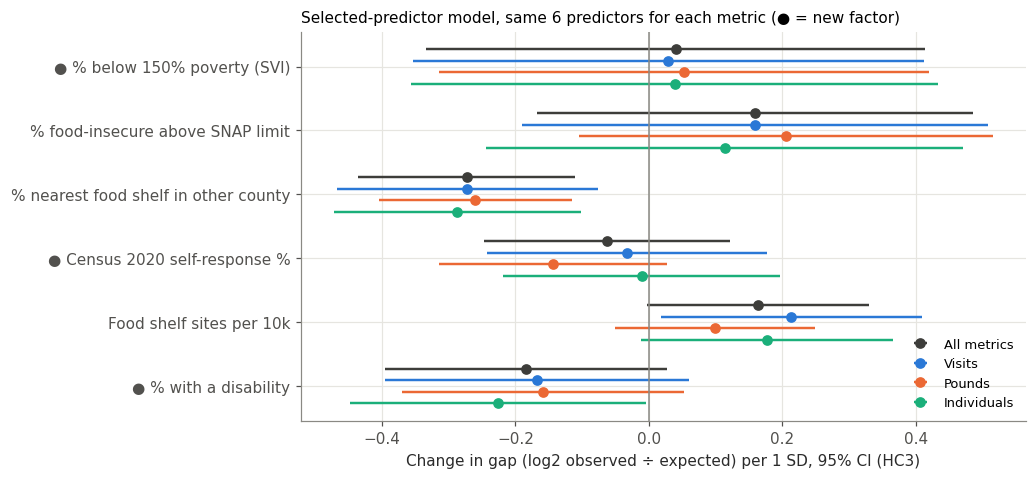

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
labs = [FAC.loc[c, "label"] for c in SEL]
off = {"All metrics": -0.27, "Visits": -0.09, "Pounds": 0.09, "Individuals": 0.27}
for olab in OUTCOMES.values():
    s = coefs[coefs["metric"] == olab].set_index("factor").loc[SEL]
    y = np.arange(len(SEL)) + off[olab]
    ax.errorbar(s["coef"], y, xerr=[s["coef"] - s["lo"], s["hi"] - s["coef"]], fmt="o", ms=6,
                color=COLOR[olab], ecolor=COLOR[olab], elinewidth=1.6, capsize=0, label=olab)
ax.axvline(0, color="#8a8984", lw=1)
ax.set_yticks(range(len(SEL))); ax.set_yticklabels([("● " if FAC.loc[c, "is_new"] else "") + l for c, l in zip(SEL, labs)])
ax.invert_yaxis()
ax.set_xlabel("Change in gap (log2 observed ÷ expected) per 1 SD, 95% CI (HC3)")
ax.set_title("Selected-predictor model, same 6 predictors for each metric (● = new factor)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8.5, loc="lower right")
fig.savefig(OUT / "q1b_coefficients.png")
plt.show()

- **Selected:** one per group, all VIF < 5: % below 150% poverty (new), % food-insecure above SNAP limit, % nearest food shelf in another county, census self-response (new), sites per 10k, % with a disability (new).
- **Only the cross-county share is clearly significant, and it is so for every metric:** about −0.27 per SD (p ≤ 0.006). Sites per 10k is borderline positive (visits p ≈ 0.03).
- **New factors:** disability leans negative (−0.16 to −0.23 per SD; p ≈ 0.05 for individuals only, and that's one of 24 coefficients). Poverty (150%) and census response are ≈ 0 once the others are held constant.
- R² ≈ 0.22–0.24 (adjusted 0.16–0.19), about the same as Q1's 7-predictor model (0.22).

## 8. Do new factors add anything beyond Q1's access and network factors?

**Baseline** = Q1's access + network model: % nearest food shelf in another county, % over 10 miles, log2 sites per 10k, food bank region.
**Full** = baseline + the new factors picked by the rule in section 7.

We report adjusted R² (R² with a penalty for each extra predictor), a robust Wald test (are all added coefficients zero?), the classic F-test, and **leave-one-out (LOO) R²**: each county is predicted by a model fitted *without* it. If LOO R² doesn't rise, the extra factors are fitting noise.

A second check adds **each new factor alone** to the baseline (27 factors × 4 outcomes = 108 tests, with FDR).

In [14]:
BASE = ["pct_nearest_other_county_z", "pct_over_10mi_z", "sites_per_10k_z", "C(main_food_bank)"]
NEW_SEL = [c for c in SEL if FAC.loc[c, "is_new"]]
print("Baseline (Q1 access + network):", BASE)
print("New factors added (those picked by the selection rule):", NEW_SEL)

def loo_r2(formula, data):
    """Leave-one-out R²: 1 - PRESS / total sum of squares (uses the hat matrix, exact for OLS)."""
    res = smf.ols(formula, data=data).fit()
    h = res.get_influence().hat_matrix_diag
    press = ((res.resid / (1 - h)) ** 2).sum()
    y = res.model.endog
    return 1 - press / ((y - y.mean()) ** 2).sum()

nest_rows = []
for oc, olab in OUTCOMES.items():
    f0 = f"{oc} ~ " + " + ".join(BASE)
    f1 = f0 + " + " + " + ".join(c + "_z" for c in NEW_SEL)
    m0 = smf.ols(f0, data=dz).fit(cov_type="HC3")
    m1 = smf.ols(f1, data=dz).fit(cov_type="HC3")
    wald = m1.wald_test(" , ".join(f"{c}_z = 0" for c in NEW_SEL), scalar=True)
    m0c, m1c = smf.ols(f0, data=dz).fit(), smf.ols(f1, data=dz).fit()
    F, pF, _ = m1c.compare_f_test(m0c)
    nest_rows.append({"metric": olab, "R² base": m0.rsquared, "R² +new": m1.rsquared,
                      "adj R² base": m0.rsquared_adj, "adj R² +new": m1.rsquared_adj,
                      "Δ adj R²": m1.rsquared_adj - m0.rsquared_adj,
                      "p (robust Wald, new=0)": float(wald.pvalue), "p (classic F)": pF,
                      "LOO R² base": loo_r2(f0, dz), "LOO R² +new": loo_r2(f1, dz)})
nested = pd.DataFrame(nest_rows).set_index("metric")
nested.round(3)

Baseline (Q1 access + network): ['pct_nearest_other_county_z', 'pct_over_10mi_z', 'sites_per_10k_z', 'C(main_food_bank)']
New factors added (those picked by the selection rule): ['pct_below_150_poverty', 'chr_pct_census_participation', 'pct_disability']


,R² base,R² +new,adj R² base,adj R² +new,Δ adj R²,"p (robust Wald, new=0)",p (classic F),LOO R² base,LOO R² +new
metric,,,,,,,,,
All metrics,0.294,0.358,0.230,0.273,0.042,0.016,0.066,0.041,0.024
Visits,0.335,0.386,0.275,0.304,0.029,0.036,0.108,0.109,0.083
Pounds,0.226,0.313,0.157,0.222,0.065,0.003,0.029,-0.017,-0.016
Individuals,0.290,0.341,0.226,0.253,0.027,0.055,0.133,0.017,-0.009


In [15]:
# One new factor at a time on top of the baseline: does ANY new factor add something? (FDR over all of these)
one_rows = []
for f in [c for c in cand.index if FAC.loc[c, "is_new"]]:
    for oc, olab in OUTCOMES.items():
        f0 = f"{oc} ~ " + " + ".join(BASE)
        m0 = smf.ols(f0, data=dz).fit(cov_type="HC3")
        m1 = smf.ols(f0 + f" + {f}_z", data=dz).fit(cov_type="HC3")
        one_rows.append({"factor": f, "label": FAC.loc[f, "label"], "metric": olab,
                         "coef (per SD)": m1.params[f + "_z"], "p": m1.pvalues[f + "_z"],
                         "Δ adj R²": m1.rsquared_adj - m0.rsquared_adj})
one = pd.DataFrame(one_rows)
one["q_fdr"] = multipletests(one["p"], method="fdr_bh")[1]
print(f"{len(one)} add-one tests | p < 0.05: {(one['p'] < ALPHA).sum()} | q < 0.05: {(one['q_fdr'] < ALPHA).sum()}")
one.sort_values("p").head(12).round(3)

108 add-one tests | p < 0.05: 12 | q < 0.05: 3


,factor,label,metric,coef (per SD),p,Δ adj R²,q_fdr
81,pct_aian,% American Indian,Visits,0.171,0.000,0.032,0.014
80,pct_aian,% American Indian,All metrics,0.161,0.000,0.033,0.015
83,pct_aian,% American Indian,Individuals,0.174,0.001,0.031,0.049
86,pct_pop_tribal_area_approx,% living in tribal area (approx.),Pounds,0.140,0.010,0.030,0.283
53,chr_pct_broadband,% households with broadband,Visits,0.237,0.013,0.056,0.289
14,median_hh_income,Median household income (SAIPE),Pounds,0.221,0.016,0.053,0.289
12,median_hh_income,Median household income (SAIPE),All metrics,0.255,0.024,0.062,0.322
82,pct_aian,% American Indian,Pounds,0.137,0.028,0.026,0.322
57,pct_no_internet,% households no internet,Visits,-0.214,0.028,0.039,0.322
52,chr_pct_broadband,% households with broadband,All metrics,0.200,0.031,0.044,0.322


- **In-sample, the three new factors add a little:** adjusted R² rises by 0.03–0.07 (robust Wald p ≈ 0.003–0.055; classic F p ≈ 0.03–0.13).
- **Out of sample, they add nothing:** LOO R² stays flat or falls (all metrics 0.04 → 0.02; visits 0.11 → 0.08; pounds −0.02 → −0.02). The small in-sample gain is overfitting.
- **One at a time:** 12 of 108 add-one tests have p < 0.05 and **3 survive FDR, all for % American Indian** (≈ +0.16 per SD for visits, individuals and all metrics). The next cell shows this is **one county**.

### 8a. Is the American Indian result real or one county?

In [16]:
# The one add-one "hit" (% American Indian): is it one county?
f0 = "mean_gap_all ~ " + " + ".join(BASE) + " + pct_aian_z"
print(d.nlargest(5, "pct_aian")[["county", "pct_aian", "main_food_bank", "mean_gap_all", "direction"]].round(2).to_string(index=False))
for name, sub in [("all 86", dz), ("without Mahnomen", dz[dz["county"] != "Mahnomen"])]:
    r = smf.ols(f0, data=sub).fit(cov_type="HC3")
    print(f"{name:>18}: % American Indian coef {r.params['pct_aian_z']:+.3f} per SD, p = {r.pvalues['pct_aian_z']:.3f}")
rk = dz.assign(aian_rank_z=lambda x: (x["pct_aian"].rank() - x["pct_aian"].rank().mean()) / x["pct_aian"].rank().std())
r = smf.ols(f0.replace("pct_aian_z", "aian_rank_z"), data=rk).fit(cov_type="HC3")
print(f"{'rank version':>18}: coef {r.params['aian_rank_z']:+.3f} per SD of rank, p = {r.pvalues['aian_rank_z']:.3f}")

    county  pct_aian           main_food_bank  mean_gap_all              direction
  Mahnomen      35.1  North Country Food Bank          1.30   higher than expected
  Beltrami      18.8  North Country Food Bank         -0.21 no persistent mismatch
      Cass       9.1 Second Harvest Northland          0.57 no persistent mismatch
      Cook       7.4 Second Harvest Northland          1.27   higher than expected
Clearwater       6.5  North Country Food Bank         -0.16 no persistent mismatch
            all 86: % American Indian coef +0.161 per SD, p = 0.000
  without Mahnomen: % American Indian coef +0.156 per SD, p = 0.435
      rank version: coef +0.078 per SD of rank, p = 0.364


**One county.** Mahnomen is 35% American Indian (almost twice the next county, Beltrami) and records about 2.5× its expected activity, even though it sits in the North Country Food Bank region, whose counties are otherwise lower. Without Mahnomen the coefficient becomes non-significant (p ≈ 0.43). With the factor as ranks (so no single county dominates) it is also non-significant (p ≈ 0.36). Mahnomen is a real and interesting case (White Earth Nation; Q1 already noted its very high hardship *and* good access), but it is not a statewide pattern.

### 8b. The 8 ACS factors: do they add anything beyond Q1's access and network factors?

Same two checks as section 8, now for the ACS factors (sample: the same counties as section 8):
1. **Add one at a time** to the baseline (8 factors × 4 outcomes = 32 tests, FDR within these 32, and also FDR over all 140 add-one tests = 108 from section 8 + 32).
2. **Nested block:** the same selection rule as section 7 applied to the ACS factors only (in each hypothesis group, the ACS factor with the largest |ρ| with the all-metrics gap; VIF < 5), added as a block to the baseline: adjusted R², robust Wald test, leave-one-out R².

In [17]:
dza = dz.join(zcols(d.loc[dz.index, ACS_Q1], ACS_Q1)[[c + "_z" for c in ACS_Q1]]) if set(dz.index) <= set(d.index) else None
assert dza is not None and dza[[c + "_z" for c in ACS_Q1]].notna().all().all()
acs_rows = []
for f in ACS_Q1:
    for oc, olab in OUTCOMES.items():
        f0 = f"{oc} ~ " + " + ".join(BASE)
        m0 = smf.ols(f0, data=dza).fit(cov_type="HC3")
        m1 = smf.ols(f0 + f" + {f}_z", data=dza).fit(cov_type="HC3")
        acs_rows.append({"factor": f, "label": FAC.loc[f, "label"], "metric": olab, "coef (per SD)": m1.params[f + "_z"],
                         "p": m1.pvalues[f + "_z"], "Δ adj R²": m1.rsquared_adj - m0.rsquared_adj})
one_acs = pd.DataFrame(acs_rows)
one_acs["q_fdr (32 ACS tests)"] = multipletests(one_acs["p"], method="fdr_bh")[1]
allp = np.r_[one["p"].values, one_acs["p"].values]
one_acs["q_fdr (all 140 add-one)"] = multipletests(allp, method="fdr_bh")[1][len(one):]
print(f"{len(one_acs)} ACS add-one tests | p < 0.05: {(one_acs['p'] < ALPHA).sum()} | q < 0.05 (32): {(one_acs['q_fdr (32 ACS tests)'] < ALPHA).sum()} "
      f"| q < 0.05 (140): {(one_acs['q_fdr (all 140 add-one)'] < ALPHA).sum()}")
display(one_acs.sort_values("p").head(8).round(3))

# Nested block: same selection rule, ACS factors only
acs_fac = FAC.loc[ACS_Q1]
picks = []
for gname, sub in acs_fac.groupby("group"):
    r = {f: abs(stats.spearmanr(dza[f], dza["mean_gap_all"])[0]) for f in sub.index}
    picks.append(max(r, key=r.get))
while True:
    X = dza[picks].apply(lambda s: (s - s.mean()) / s.std()).assign(const=1.0)
    vifs = pd.Series([variance_inflation_factor(X.values, i) for i in range(len(picks))], index=picks)
    if vifs.max() < 5 or len(picks) == 1:
        break
    picks.remove(vifs.idxmax())
ACS_SEL = picks
print("ACS block (one per group, VIF < 5):", [FAC.loc[c, "label"] for c in ACS_SEL])
nest_acs = []
for oc, olab in OUTCOMES.items():
    f0 = f"{oc} ~ " + " + ".join(BASE)
    f1 = f0 + " + " + " + ".join(c + "_z" for c in ACS_SEL)
    m0 = smf.ols(f0, data=dza).fit(cov_type="HC3"); m1 = smf.ols(f1, data=dza).fit(cov_type="HC3")
    wald = m1.wald_test(" , ".join(f"{c}_z = 0" for c in ACS_SEL), scalar=True)
    nest_acs.append({"metric": olab, "adj R² base": m0.rsquared_adj, "adj R² +ACS": m1.rsquared_adj,
                     "Δ adj R²": m1.rsquared_adj - m0.rsquared_adj, "p (robust Wald, ACS=0)": float(wald.pvalue),
                     "LOO R² base": loo_r2(f0, dza), "LOO R² +ACS": loo_r2(f1, dza)})
nested_acs = pd.DataFrame(nest_acs).set_index("metric")
nested_acs.round(3)

32 ACS add-one tests | p < 0.05: 0 | q < 0.05 (32): 0 | q < 0.05 (140): 0


,factor,label,metric,coef (per SD),p,Δ adj R²,q_fdr (32 ACS tests),q_fdr (all 140 add-one)
23,pct_nonwhite,% non-white or Hispanic (ACS),Individuals,0.162,0.092,0.026,0.934,0.587
6,pct_hh_severe_burden_50,% households severely burdened ≥50% (ACS),Pounds,-0.118,0.158,0.016,0.934,0.663
4,pct_hh_severe_burden_50,% households severely burdened ≥50% (ACS),All metrics,-0.096,0.250,0.005,0.934,0.753
7,pct_hh_severe_burden_50,% households severely burdened ≥50% (ACS),Individuals,-0.098,0.273,0.003,0.934,0.753
20,pct_nonwhite,% non-white or Hispanic (ACS),All metrics,0.106,0.312,0.009,0.934,0.753
21,pct_nonwhite,% non-white or Hispanic (ACS),Visits,0.109,0.342,0.008,0.934,0.771
26,pct_65plus_living_alone,% of 65+ living alone (ACS),Pounds,-0.068,0.416,-0.001,0.934,0.792
5,pct_hh_severe_burden_50,% households severely burdened ≥50% (ACS),Visits,-0.071,0.417,-0.002,0.934,0.792


ACS block (one per group, VIF < 5): ['% households severely burdened ≥50% (ACS)', '% households on SNAP (ACS)', '% non-white or Hispanic (ACS)', '% of 65+ living alone (ACS)']


,adj R² base,adj R² +ACS,Δ adj R²,"p (robust Wald, ACS=0)",LOO R² base,LOO R² +ACS
metric,,,,,,
All metrics,0.230,0.251,0.020,0.440,0.041,-0.034
Visits,0.275,0.279,0.004,0.682,0.109,0.013
Pounds,0.157,0.170,0.013,0.413,-0.017,-0.113
Individuals,0.226,0.266,0.039,0.305,0.017,-0.024


- **One at a time:** none of the 32 ACS add-one tests reaches even p < 0.05 (smallest: % non-white for individuals, p ≈ 0.09). Nothing survives FDR, whether within the 32 or across all 140 add-one tests.
- **As a block** (severe housing burden, % households on SNAP, % non-white, seniors living alone; all VIF < 5): adjusted R² rises by only 0.00–0.04, the robust Wald test is far from significant (p = 0.31–0.68), and **leave-one-out R² falls** for every metric (all metrics 0.04 → −0.03). The ACS factors add noise, not explanation.
- So the access/network baseline stays the best model; the ACS factors don't change any conclusion of sections 7–9 (which keep the first version's candidate list).

### 8c. Three more datasets (`06c_extra_factors.ipynb`): cost of living, SNAP retailers, WIC

Nine new county factors, tested exactly like the others (Spearman with each gap + FDR; then add-one and nested-block models on the Q1 access/network baseline, with leave-one-out R²):

| Factor | Source | Group | Expected link |
|---|---|---|---|
| Affordability gap: family-of-3 budget ÷ median income | MN DEED cost of living ÷ SAIPE 2024 | a. Hardship | ≈ 0 (hardship is inside MMG) |
| Family-of-3 yearly budget | MN DEED | a. Hardship | ? |
| Family-of-3 monthly food cost | MN DEED | a. Hardship | + (dearer food → more food shelf use) |
| Single-adult required hourly wage | MN DEED | a. Hardship | ? |
| SNAP retailers per 10k (2022–24 avg) | USDA FNS retailer locator | c. Access | ? |
| Full-service SNAP stores per 10k (2022–24 avg) | USDA FNS | c. Access | ? |
| Miles to nearest full-service SNAP store (2024, pop-weighted) | USDA FNS + Census block groups | c. Access | − (remote) |
| Net change in SNAP retailers per 10k, 2022→2025 | USDA FNS | c. Access | − (closures) |
| WIC infants + children per 100 children under 5 (2022) | MN Dept. of Health | b. Eligibility / program uptake | ? |

DEED is one edition (no year), WIC is 2022 (latest available), so all nine are cross-sectional.

**Test count.** 9 factors × 4 outcomes = **36 new tests**, so the Spearman family grows from **188 to 224**. To keep earlier numbers checkable, the saved table **keeps `q_fdr` for the original 188 rows unchanged** (their 188-test family) and adds a column **`q_fdr_incl_06c`** = FDR over all 224 tests (filled for every row). For the 36 new rows, `q_fdr` is the 224-test value.

In [18]:
ex_s = pd.read_csv(PROCESSED / "county_extra_factors_static.csv", dtype={"fips": str}).set_index("fips")
ex_y = pd.read_csv(PROCESSED / "county_extra_factors.csv", dtype={"fips": str})
assert ex_y["year"].max() <= 2025      # nothing dated August 2026 or later
X06C = pd.DataFrame(index=ex_s.index)
for c in ["col_affordability_gap_fam3", "col_yearly_cost_fam3", "col_food_monthly_fam3", "col_required_hourly_wage_single",
          "snap_full_mean_dist_mi_2024", "snap_net_change_per_10k_2022_2025"]:
    X06C[c] = ex_s[c]
X06C = X06C.join(ex_y[ex_y["year"].between(2022, 2024)].groupby("fips")[["snap_retailers_per_10k", "snap_full_service_per_10k"]].mean())
X06C = X06C.join(ex_y[ex_y["year"] == 2022].set_index("fips")[["wic_infants_children_per_100_under5"]])
F06C = [
 ("col_affordability_gap_fam3",          "Affordability gap: DEED budget / income (06c)", "a. Hardship/economy", "-/0"),
 ("col_yearly_cost_fam3",                "DEED family-of-3 yearly budget (06c)",          "a. Hardship/economy", "?"),
 ("col_food_monthly_fam3",               "DEED family-of-3 monthly food cost (06c)",      "a. Hardship/economy", "+"),
 ("col_required_hourly_wage_single",     "DEED required hourly wage, single adult (06c)", "a. Hardship/economy", "?"),
 ("wic_infants_children_per_100_under5", "WIC infants+children per 100 under 5 (06c)",    "b. Eligibility gaps", "?"),
 ("snap_retailers_per_10k",              "SNAP retailers per 10k (06c)",                  "c. Physical access",  "?"),
 ("snap_full_service_per_10k",           "Full-service SNAP stores per 10k (06c)",        "c. Physical access",  "?"),
 ("snap_full_mean_dist_mi_2024",         "Miles to nearest full-service SNAP store (06c)", "c. Physical access", "-"),
 ("snap_net_change_per_10k_2022_2025",   "Net change SNAP retailers per 10k 2022-25 (06c)", "c. Physical access", "-"),
]
FAC6 = pd.DataFrame(F06C, columns=["factor", "label", "group", "hyp_sign"]).set_index("factor")
BATCH6 = "06c extra (DEED / SNAP retailers / WIC)"
d6 = d.drop(columns=[c for c in FAC6.index if c in d.columns]).merge(X06C.reset_index(), on="fips", how="left", validate="one_to_one")
assert d6[list(FAC6.index)].notna().all().all() and len(d6) == 86

rows6 = []
for f, meta in FAC6.iterrows():
    for oc, olab in OUTCOMES.items():
        rho, p = stats.spearmanr(d6[f], d6[oc])
        rows6.append({"factor": f, "label": meta["label"], "group": meta["group"], "is_new": True, "metric": olab,
                      "test": "spearman", "n": 86, "rho": rho, "p": p, "batch": BATCH6})
t6 = pd.DataFrame(rows6)
allt = pd.concat([tests.assign(_orig=True), t6.assign(_orig=False)], ignore_index=True)
allt["q_fdr_incl_06c"] = multipletests(allt["p"], method="fdr_bh")[1]
allt["q_fdr_within_metric_incl_06c"] = allt.groupby("metric")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
new = ~allt["_orig"]
allt.loc[new, "q_fdr"] = allt.loc[new, "q_fdr_incl_06c"]
allt.loc[new, "q_fdr_within_metric"] = allt.loc[new, "q_fdr_within_metric_incl_06c"]
allt.loc[new, "survives_fdr"] = allt.loc[new, "q_fdr"] < ALPHA
allt.loc[new, "direction"] = np.where(allt.loc[new, "rho"] > 0, "higher factor -> more activity than expected", "higher factor -> less activity than expected")
print(f"Spearman family: {len(tests)} + {len(t6)} = {len(allt)} tests | 06c tests with p < 0.05: {(t6['p'] < ALPHA).sum()} of {len(t6)} "
      f"(about {ALPHA * len(t6):.1f} expected by chance) | q < 0.05 (224-test FDR): {(allt.loc[new, 'q_fdr_incl_06c'] < ALPHA).sum()} "
      f"| q < 0.05 (within-metric): {(allt.loc[new, 'q_fdr_within_metric_incl_06c'] < ALPHA).sum()}")
print(f"Original tests passing FDR over all 224: {(allt.loc[~new, 'q_fdr_incl_06c'] < ALPHA).sum()} (smallest q = {allt.loc[~new, 'q_fdr_incl_06c'].min():.3f}; "
      f"was {tests['q_fdr'].min():.3f} over 188)")
wm = allt.loc[~new & (allt["q_fdr_within_metric_incl_06c"] < ALPHA)]
print(f"Original tests passing within-metric FDR incl. 06c (56 tests per metric): {len(wm)} "
      f"(smallest: {allt.loc[~new, 'q_fdr_within_metric_incl_06c'].min():.3f}; was {tests['q_fdr_within_metric'].min():.3f} with 47 per metric)")
display(allt[new].pivot_table(index="label", columns="metric", values="rho", sort=False)[list(OUTCOMES.values())]
        .join(allt[new & (allt["metric"] == "All metrics")].set_index("label")[["p", "q_fdr_incl_06c"]]).round(3))

# Save: original rows unchanged (asserted), 36 rows appended, one new column
save6 = allt[save_cols + ["q_fdr_incl_06c"]]
assert_unchanged(save6, n=len(tests))
save6.to_csv(TESTS_CSV, index=False)
print("Saved", TESTS_CSV.name, save6.shape)

Spearman family: 188 + 36 = 224 tests | 06c tests with p < 0.05: 0 of 36 (about 1.8 expected by chance) | q < 0.05 (224-test FDR): 0 | q < 0.05 (within-metric): 0
Original tests passing FDR over all 224: 0 (smallest q = 0.117; was 0.098 over 188)
Original tests passing within-metric FDR incl. 06c (56 tests per metric): 0 (smallest: 0.058; was 0.049 with 47 per metric)


,All metrics,Visits,Pounds,Individuals,p,q_fdr_incl_06c
label,,,,,,
Affordability gap: DEED budget / income (06c),-0.083,-0.035,-0.129,-0.093,0.450,0.747
DEED family-of-3 yearly budget (06c),0.107,0.144,0.085,0.092,0.325,0.747
DEED family-of-3 monthly food cost (06c),0.108,0.066,0.145,0.115,0.320,0.747
"DEED required hourly wage, single adult (06c)",0.107,0.133,0.111,0.104,0.328,0.747
WIC infants+children per 100 under 5 (06c),-0.084,-0.101,-0.126,-0.039,0.441,0.747
SNAP retailers per 10k (06c),-0.032,0.008,-0.068,-0.015,0.769,0.893
Full-service SNAP stores per 10k (06c),0.095,0.085,0.106,0.095,0.382,0.747
Miles to nearest full-service SNAP store (06c),-0.109,-0.117,-0.074,-0.125,0.317,0.747
Net change SNAP retailers per 10k 2022-25 (06c),0.071,0.064,0.023,0.085,0.516,0.799


Saved q1b_factor_tests.csv (224, 16)


**Add one at a time, and as a block,** on top of the Q1 access + network baseline (same sample, same baseline as sections 8 and 8b).

In [19]:
dz6 = dz.join(zcols(d6.set_index(dz.index), list(FAC6.index))[[c + "_z" for c in FAC6.index]])
assert dz6[[c + "_z" for c in FAC6.index]].notna().all().all() and (d6.set_index(dz.index)["fips"] == dz["fips"]).all()
r6 = []
for f in FAC6.index:
    for oc, olab in OUTCOMES.items():
        f0 = f"{oc} ~ " + " + ".join(BASE)
        m0 = smf.ols(f0, data=dz6).fit(cov_type="HC3"); m1 = smf.ols(f0 + f" + {f}_z", data=dz6).fit(cov_type="HC3")
        r6.append({"factor": f, "label": FAC6.loc[f, "label"], "metric": olab, "coef (per SD)": m1.params[f + "_z"],
                   "p": m1.pvalues[f + "_z"], "Δ adj R²": m1.rsquared_adj - m0.rsquared_adj})
one6 = pd.DataFrame(r6)
one6["q_fdr (36 tests)"] = multipletests(one6["p"], method="fdr_bh")[1]
allp = np.r_[one["p"].values, one_acs["p"].values, one6["p"].values]
one6["q_fdr (all 176 add-one)"] = multipletests(allp, method="fdr_bh")[1][len(one) + len(one_acs):]
print(f"{len(one6)} add-one tests | p < 0.05: {(one6['p'] < ALPHA).sum()} | q < 0.05 (36): {(one6['q_fdr (36 tests)'] < ALPHA).sum()} "
      f"| q < 0.05 (176): {(one6['q_fdr (all 176 add-one)'] < ALPHA).sum()}")
display(one6.sort_values("p").head(8).round(3))

# Nested block: same selection rule (best |rho| with the all-metrics gap in each group, VIF < 5)
picks = []
for gname, sub in FAC6.groupby("group"):
    r = {f: abs(stats.spearmanr(d6[f], d6["mean_gap_all"])[0]) for f in sub.index}
    picks.append(max(r, key=r.get))
while True:
    X = dz6[[c + "_z" for c in picks]].assign(const=1.0)
    vifs = pd.Series([variance_inflation_factor(X.values, i) for i in range(len(picks))], index=picks)
    if vifs.max() < 5 or len(picks) == 1:
        break
    picks.remove(vifs.idxmax())
SEL6 = picks
print("06c block (one per group, VIF < 5):", [FAC6.loc[c, "label"] for c in SEL6])
n6 = []
for oc, olab in OUTCOMES.items():
    f0 = f"{oc} ~ " + " + ".join(BASE); f1 = f0 + " + " + " + ".join(c + "_z" for c in SEL6)
    m0 = smf.ols(f0, data=dz6).fit(cov_type="HC3"); m1 = smf.ols(f1, data=dz6).fit(cov_type="HC3")
    wald = m1.wald_test(" , ".join(f"{c}_z = 0" for c in SEL6), scalar=True)
    n6.append({"metric": olab, "adj R² base": m0.rsquared_adj, "adj R² +06c": m1.rsquared_adj, "Δ adj R²": m1.rsquared_adj - m0.rsquared_adj,
               "p (robust Wald, 06c=0)": float(wald.pvalue), "LOO R² base": loo_r2(f0, dz6), "LOO R² +06c": loo_r2(f1, dz6)})
nested6 = pd.DataFrame(n6).set_index("metric")
nested6.round(3)

36 add-one tests | p < 0.05: 4 | q < 0.05 (36): 0 | q < 0.05 (176): 0


,factor,label,metric,coef (per SD),p,Δ adj R²,q_fdr (36 tests),q_fdr (all 176 add-one)
13,col_required_hourly_wage_single,"DEED required hourly wage, single adult (06c)",Visits,0.267,0.019,0.059,0.338,0.443
2,col_affordability_gap_fam3,Affordability gap: DEED budget / income (06c),Pounds,-0.151,0.033,0.031,0.338,0.443
12,col_required_hourly_wage_single,"DEED required hourly wage, single adult (06c)",All metrics,0.226,0.038,0.047,0.338,0.443
5,col_yearly_cost_fam3,DEED family-of-3 yearly budget (06c),Visits,0.229,0.042,0.044,0.338,0.461
15,col_required_hourly_wage_single,"DEED required hourly wage, single adult (06c)",Individuals,0.252,0.052,0.048,0.338,0.480
3,col_affordability_gap_fam3,Affordability gap: DEED budget / income (06c),Individuals,-0.137,0.066,0.014,0.338,0.503
0,col_affordability_gap_fam3,Affordability gap: DEED budget / income (06c),All metrics,-0.130,0.066,0.017,0.338,0.503
4,col_yearly_cost_fam3,DEED family-of-3 yearly budget (06c),All metrics,0.183,0.086,0.030,0.352,0.523


06c block (one per group, VIF < 5): ['DEED family-of-3 monthly food cost (06c)', 'WIC infants+children per 100 under 5 (06c)', 'Miles to nearest full-service SNAP store (06c)']


,adj R² base,adj R² +06c,Δ adj R²,"p (robust Wald, 06c=0)",LOO R² base,LOO R² +06c
metric,,,,,,
All metrics,0.230,0.208,-0.022,0.942,0.041,-0.094
Visits,0.275,0.251,-0.024,0.962,0.109,-0.009
Pounds,0.157,0.147,-0.010,0.698,-0.017,-0.158
Individuals,0.226,0.205,-0.021,0.865,0.017,-0.104


**Result (8c): the three new datasets explain nothing beyond Q1's access and network factors.**
- **One factor at a time:** none of the 36 new Spearman tests reaches even p < 0.05 (about 2 would by chance). All |ρ| ≤ 0.15; on the all-metrics gap: affordability gap −0.08, DEED food cost +0.11, SNAP retailers per 10k −0.03, full-service SNAP stores per 10k +0.10, **miles to the nearest full-service SNAP store −0.11** (p = 0.32), net change in SNAP retailers +0.07, WIC uptake per young child −0.08. Smallest q (224-test FDR) = 0.75.
- **Bigger family, same answer for the old factors:** with 224 tests the strongest factor (% nearest food shelf in another county) has q = 0.12 (0.10 over 188); still nothing passes the all-tests FDR. The saved `q_fdr` for the original 188 rows is unchanged; `q_fdr_incl_06c` holds the 224-test values.
- **Added to the access/network baseline:** 4 of 36 add-one tests have p < 0.05 (DEED single-adult required wage, visits, +0.27 per SD, p = 0.02; affordability gap, pounds, −0.15, p = 0.03; family budget, visits), **none survives FDR** (q ≥ 0.34 within these 36; ≥ 0.44 over all 176 add-one tests). These DEED cost measures are metro-high, so they echo the metro/hub pattern already in the baseline.
- **As a block** (DEED food cost, WIC uptake, distance to a full-service SNAP store; VIF < 5): adjusted R² **falls** (−0.01 to −0.02), robust Wald p = 0.70–0.96, and **leave-one-out R² falls for every metric** (all metrics 0.04 → −0.09).
- **Distance to a grocery store is not distance to a food shelf.** The two distances correlate (ρ = 0.71 across counties), yet only the food shelf one lines up with the mismatch (−0.24 vs −0.11). Same lesson as the CBP and USDA grocery measures in section 5: what matters is the food shelf network.

## 9. Cross-validated sanity checks

1. **Leave-one-out with the selection rule re-run inside every fold.** Picking predictors on all 86 counties and then testing on the same counties flatters the model. Here, each held-out county is predicted by a model whose predictors were chosen *without* it.
2. **Random forest** on all candidate factors + food bank dummies, with out-of-bag R² (each county predicted by trees that never saw it) and permutation importance (how much the fit worsens when one factor is shuffled).

In [20]:
# Honest check: leave-one-out with the SELECTION RULE re-run inside every fold (so selection can't peek at the held-out county)
def loo_with_selection(data, outcome):
    preds = []
    for i in data.index:
        train = data.drop(index=i)
        picks, _ = select_predictors(train, outcome="mean_gap_all")
        tz = train.copy(); te = data.loc[[i]].copy()
        for c in picks:
            mu, sd = train[c].mean(), train[c].std()
            tz[c + "_z"] = (train[c] - mu) / sd; te[c + "_z"] = (te[c] - mu) / sd
        res = smf.ols(f"{outcome} ~ " + " + ".join(c + "_z" for c in picks), data=tz).fit()
        preds.append(float(res.predict(te).iloc[0]))
    y = data[outcome]
    return 1 - ((y - np.array(preds)) ** 2).sum() / ((y - y.mean()) ** 2).sum()

cv_rows = []
for oc, olab in OUTCOMES.items():
    cv_rows.append({"metric": olab,
                    "in-sample R² (selected 6)": fits[olab].rsquared,
                    "LOO R² (selection inside folds)": loo_with_selection(dm, oc),
                    "LOO R² baseline (Q1 access + food bank)": nested.loc[olab, "LOO R² base"]})
cv = pd.DataFrame(cv_rows).set_index("metric")
cv.round(3)

,in-sample R² (selected 6),LOO R² (selection inside folds),LOO R² baseline (Q1 access + food bank)
metric,,,
All metrics,0.238,0.060,0.041
Visits,0.227,0.049,0.109
Pounds,0.243,0.090,-0.017
Individuals,0.217,0.020,0.017


In [21]:
# Sanity check with a different method: random forest on ALL candidate factors + food bank dummies (all-metrics gap)
Xrf = pd.concat([dm[list(cand.index)], pd.get_dummies(dm["main_food_bank"], prefix="fb", dtype=float)], axis=1)
yrf = dm["mean_gap_all"]
rf = RandomForestRegressor(n_estimators=1000, min_samples_leaf=3, max_features=0.33, oob_score=True, random_state=42)
rf.fit(Xrf, yrf)
print(f"Random forest out-of-bag R² = {rf.oob_score_:.2f} (out-of-bag = each county predicted by trees that never saw it)")
imp = permutation_importance(rf, Xrf, yrf, n_repeats=30, random_state=42)
imp_s = pd.Series(imp.importances_mean, index=Xrf.columns).sort_values(ascending=False)
lab = lambda c: FAC.loc[c, "label"] + (" (new)" if FAC.loc[c, "is_new"] else "") if c in FAC.index else c
imp_s.head(10).rename(index=lab).round(4).to_frame("permutation importance (in-sample)")

Random forest out-of-bag R² = 0.03 (out-of-bag = each county predicted by trees that never saw it)


,permutation importance (in-sample)
% nearest food shelf in other county,0.1217
% low-income housing cost burden (new),0.0673
Food shelf sites per 10k,0.0568
Avg miles to nearest food shelf,0.0524
% with a disability (new),0.0476
% residents >10 mi from food shelf,0.0420
Median household income (SAIPE) (new),0.0308
Census 2020 self-response % (new),0.0283
Rural share % (2020),0.0264
Unemployment rate (BLS) (new),0.0244


- **Out-of-sample predictive power is very low for every model**: LOO R² ≈ 0.02–0.09 for the selected model, 0.04–0.11 for the baseline; random forest out-of-bag R² ≈ 0.03.
- So the factors are **associated** with the mismatch on average (the cross-county share especially), but **no combination of public county characteristics can predict which counties will be off**. Most of the mismatch is county-specific: local site practices, a single large regional food shelf, reporting habits.
- The random forest's top factor is again **% nearest food shelf in another county**, well ahead of the rest. That's the same answer from a completely different method.

## 10. Do the three metrics need different explanations?

Two checks:
1. **Are the factor profiles alike?** Correlate the 46 factor-ρ values between metrics.
2. **What explains the *difference* between gaps?** If pounds and visits behave differently, the difference `pounds gap − visits gap` (≈ food per visit relative to expected) should correlate with something; likewise `individuals gap − visits gap` (≈ people per visit). FDR across these 94 tests (46 factors × 2 + 2 food bank tests).

In [22]:
# Do the three metrics have different explanations? Two direct checks:
# 1) how similar are the factor-rho profiles across metrics?
prof_rho = tests[tests["test"] == "spearman"].pivot(index="factor", columns="metric", values="rho")
print(f"Correlation of the {len(FAC)} factor rhos between metrics:")
display(prof_rho[["Visits", "Pounds", "Individuals"]].corr().round(2))
print("Between-county correlation of the gaps themselves (Spearman):")
display(d[["visits_mean_gap", "pounds_mean_gap", "individuals_mean_gap"]].corr(method="spearman").round(2))

# 2) differences between gaps = what is left once the shared part is removed
d["pounds_vs_visits"] = d["pounds_mean_gap"] - d["visits_mean_gap"]          # food per visit, relative to expected
d["indiv_vs_visits"] = d["individuals_mean_gap"] - d["visits_mean_gap"]      # people per visit, relative to expected
diff_rows = []
for f, meta in FAC.iterrows():
    for oc in ["pounds_vs_visits", "indiv_vs_visits"]:
        sub = d[[f, oc]].dropna()
        rho, p = stats.spearmanr(sub[f], sub[oc])
        diff_rows.append({"factor": f, "label": meta["label"], "group": meta["group"], "outcome": oc, "rho": rho, "p": p})
for oc in ["pounds_vs_visits", "indiv_vs_visits"]:
    sub = d[["main_food_bank", oc]].dropna()
    diff_rows.append({"factor": "main_food_bank", "label": "Main food bank (KW)", "group": "e. Network/supply", "outcome": oc,
                      "rho": np.nan, "p": stats.kruskal(*[g[oc] for _, g in sub.groupby("main_food_bank")]).pvalue})
diff = pd.DataFrame(diff_rows)
diff["q_fdr"] = multipletests(diff["p"], method="fdr_bh")[1]
print(f"{len(diff)} tests on the metric differences | p < 0.05: {(diff['p'] < ALPHA).sum()} | q < 0.05: {(diff['q_fdr'] < ALPHA).sum()}")
diff.sort_values("p").head(10).round(3)

Correlation of the 46 factor rhos between metrics:


metric,Visits,Pounds,Individuals
metric,,,
Visits,1.00,0.89,0.96
Pounds,0.89,1.00,0.85
Individuals,0.96,0.85,1.00


Between-county correlation of the gaps themselves (Spearman):


,visits_mean_gap,pounds_mean_gap,individuals_mean_gap
visits_mean_gap,1.00,0.81,0.94
pounds_mean_gap,0.81,1.00,0.85
individuals_mean_gap,0.94,0.85,1.00


94 tests on the metric differences | p < 0.05: 11 | q < 0.05: 5


,factor,label,group,outcome,rho,p,q_fdr
92,main_food_bank,Main food bank (KW),e. Network/supply,pounds_vs_visits,NaN,0.000,0.010
71,pct_foreign_born,% foreign-born (ACS),d. Awareness/stigma/social,indiv_vs_visits,0.386,0.000,0.010
73,pct_nonwhite,% non-white or Hispanic (ACS),d. Awareness/stigma/social,indiv_vs_visits,0.378,0.000,0.010
83,pct_age_17under,% under 18,f. Demographics,indiv_vs_visits,0.372,0.000,0.010
69,pct_hispanic,% Hispanic,d. Awareness/stigma/social,indiv_vs_visits,0.354,0.001,0.016
57,pct_limited_english,% limited English,d. Awareness/stigma/social,indiv_vs_visits,0.311,0.004,0.056
1,unemployment_rate,Unemployment rate (BLS),a. Hardship/economy,indiv_vs_visits,-0.240,0.026,0.351
81,pct_age_65plus,% age 65+,f. Demographics,indiv_vs_visits,-0.234,0.030,0.354
60,chr_pct_census_participation,Census 2020 self-response %,d. Awareness/stigma/social,pounds_vs_visits,-0.226,0.036,0.357
76,visits_per_site_month,Visits per site-month (circular),e. Network/supply,pounds_vs_visits,-0.224,0.038,0.357


In [23]:
print("Pounds-vs-visits gap by food bank (median, log2; negative = less food per visit than expected):")
d.groupby("main_food_bank")[["pounds_vs_visits", "indiv_vs_visits"]].agg(["median", "size"]).round(2)

Pounds-vs-visits gap by food bank (median, log2; negative = less food per visit than expected):


pounds_vs_visits      indiv_vs_visits     
                                         median size          median size
main_food_bank                                                           
Channel One Regional Food Bank            -0.40   13           -0.05   13
North Country Food Bank                    0.09   21            0.01   21
Second Harvest Heartland                   0.07   39            0.11   39
Second Harvest Northland                  -0.05   11           -0.19   11
The Food Group                            -0.30    2            0.00    2

- **Same explanation for all three metrics.** The factor-ρ profiles correlate 0.85–0.96, and the gaps themselves correlate 0.81–0.94 across counties. The access/network pattern isn't specific to one metric.
- **But the differences between metrics do have explanations (5 of 94 tests survive FDR):**
  - **Pounds vs. visits differs by food bank** (q ≈ 0.01). Channel One counties give **less food per visit** than expected (median −0.40 log2, ≈ 0.76×); North Country and Second Harvest Heartland ≈ 0. So **pounds is shaped by supply/distribution practice**, not access. North Country counties are low on *every* metric, not on food per visit.
  - **Individuals vs. visits is higher where there are more foreign-born residents (ρ ≈ +0.39, new ACS), more non-white or Hispanic residents (+0.38, ACS), more children (+0.37) and more Hispanic residents (+0.35)**, with limited English close behind (+0.31, q ≈ 0.06). That's **household size**: larger households mean more people per visit. It's composition, not a barrier.
- **Answer to "pounds = supply, visits = access?"** Partly. Access explains the shared part of all three gaps. The food bank network explains the extra pounds-specific part. Household composition explains the individuals-specific part.

## 11. Over time: does a worsening economy move a county above or below MMG's expectation?

The static analysis compares counties with each other. Here we ask: within the same county, from 2022 to 2024, does the gap change when unemployment, poverty or income change?

In [24]:
# Within-county change 2022 -> 2024: does a county whose economy worsened drift above MMG's expectation?
gw = cy.pivot(index="fips", columns="year", values=[f"{m}_gap" for m in METRICS])
fw = fy.pivot(index="fips", columns="year", values=["unemployment_rate", "saipe_poverty_rate", "median_hh_income"])
ch = pd.DataFrame({f"Δ {m} gap": gw[(f"{m}_gap", 2024)] - gw[(f"{m}_gap", 2022)] for m in METRICS})
ch["Δ unemployment (pp)"] = fw[("unemployment_rate", 2024)] - fw[("unemployment_rate", 2022)]
ch["Δ SAIPE poverty (pp)"] = fw[("saipe_poverty_rate", 2024)] - fw[("saipe_poverty_rate", 2022)]
ch["% change median income"] = (fw[("median_hh_income", 2024)] / fw[("median_hh_income", 2022)] - 1) * 100
ch = ch.dropna()
rows = []
for x in ["Δ unemployment (pp)", "Δ SAIPE poverty (pp)", "% change median income"]:
    for m in METRICS:
        rho, p = stats.spearmanr(ch[x], ch[f"Δ {m} gap"])
        rows.append({"change in": x, "metric": m, "rho": rho, "p": p})
chg = pd.DataFrame(rows)
chg["q_fdr"] = multipletests(chg["p"], method="fdr_bh")[1]
print("Counties:", len(ch))
display(chg.round(3))
chg.pivot(index="change in", columns="metric", values="rho").round(2).join(
    chg.pivot(index="change in", columns="metric", values="p").round(2), rsuffix=" p")

Counties: 86


,change in,metric,rho,p,q_fdr
0,Δ unemployment (pp),visits,0.036,0.743,0.836
1,Δ unemployment (pp),pounds,-0.114,0.296,0.380
2,Δ unemployment (pp),individuals,0.017,0.880,0.880
3,Δ SAIPE poverty (pp),visits,-0.297,0.006,0.025
4,Δ SAIPE poverty (pp),pounds,-0.196,0.071,0.159
5,Δ SAIPE poverty (pp),individuals,-0.298,0.005,0.025
6,% change median income,visits,0.128,0.239,0.359
7,% change median income,pounds,0.177,0.103,0.186
8,% change median income,individuals,0.199,0.066,0.159


metric,individuals,pounds,visits,individuals p,pounds p,visits p
change in,,,,,,
% change median income,0.20,0.18,0.13,0.07,0.10,0.24
Δ SAIPE poverty (pp),-0.30,-0.20,-0.30,0.01,0.07,0.01
Δ unemployment (pp),0.02,-0.11,0.04,0.88,0.30,0.74


- **Rising poverty goes with a falling gap** (visits and individuals ρ ≈ −0.30, p ≈ 0.005, q ≈ 0.03 within these 9 tests; pounds −0.20, q ≈ 0.16). Changes in unemployment and income: nothing that survives correction.
- This is what we'd expect if **MMG's need estimate moves with poverty but food shelf activity doesn't**. When poverty rises, MMG's expected need rises, activity doesn't follow, and the gap shrinks. It's another sign that hardship lives inside the MMG estimate, not in the mismatch.
- Caveat: SAIPE year-to-year changes in small counties are noisy (wide margins of error).

## 12. Robustness

1. Grocery stores without the midpoint guess for the 17 suppressed counties.
2. The strongest factors without Douglas, Grant and Stevens (the possible data-quality cases from Q1 section 34).

In [25]:
# 1) Grocery stores without the midpoint guess (drop the 17 suppressed counties)
# 2) Drop the three possible data-quality counties from Q1 (Douglas, Grant, Stevens)
top = tests[(tests["metric"] == "All metrics") & (tests["test"] == "spearman")].nsmallest(8, "p")["factor"].tolist()
rob = []
dq = d[~d["county"].isin(["Douglas", "Grant", "Stevens"])]
for f in dict.fromkeys(top + ["grocery_stores_per_10k"]):
    r_all = stats.spearmanr(d[f], d["mean_gap_all"], nan_policy="omit")
    r_dq = stats.spearmanr(dq[f], dq["mean_gap_all"], nan_policy="omit")
    rob.append({"label": FAC.loc[f, "label"], "rho (86)": r_all[0], "rho w/o Douglas/Grant/Stevens": r_dq[0], "p w/o": r_dq[1]})
sub = d[~d["grocery_suppressed"]]
r_g = stats.spearmanr(sub["grocery_stores_per_10k_reported"], sub["mean_gap_all"], nan_policy="omit")
print(f"Grocery stores per 10k, reported counties only (n={sub['grocery_stores_per_10k_reported'].notna().sum()}): rho = {r_g[0]:.2f}, p = {r_g[1]:.2f}")
pd.DataFrame(rob).round(3)

Grocery stores per 10k, reported counties only (n=69): rho = -0.02, p = 0.90


,label,rho (86),rho w/o Douglas/Grant/Stevens,p w/o
0,% nearest food shelf in other county,-0.334,-0.373,0.001
1,% residents >10 mi from food shelf,-0.273,-0.261,0.017
2,Food shelf sites per 10k,0.251,0.252,0.021
3,Avg miles to nearest food shelf,-0.238,-0.228,0.038
4,Visits per site-month (circular),0.235,0.239,0.029
5,% below 150% poverty (SVI),-0.197,-0.203,0.066
6,% low-income housing cost burden,-0.171,-0.165,0.135
7,"Poverty rate (ACS, Q1)",-0.162,-0.170,0.123
8,Grocery stores per 10k (CBP),-0.022,-0.036,0.750


- **Grocery stores stay at zero** with or without the suppressed counties (ρ ≈ −0.02).
- Dropping the three data-quality counties changes nothing: the cross-county share gets slightly stronger (ρ ≈ −0.37). No ACS factor is among the 8 strongest, so none needed a robustness check.

## 13. Conclusions (plain language)

**Which new factors matter?** **None, after correcting for the number of tests** (188 tests: 27 factors from `06a` + 8 ACS factors from the Census API + Q1's own; **224** with the 9 factors from `06c` in section 8c).
- Of 140 tests on new factors, only 2 reached p < 0.05: fewer than chance alone would produce.
- The one new factor that passed FDR when added to the access model, **% American Indian**, is entirely **Mahnomen County** (35% American Indian, 2.5× expected activity). Without Mahnomen it disappears (p ≈ 0.43).
- Adding the best new factors raises in-sample adjusted R² by 0.03–0.07, but **leave-one-out R² doesn't improve**, so the gain is noise. The same holds for the ACS block (section 8b): LOO R² falls.
- **Three more datasets (section 8c): MN DEED cost of living, USDA SNAP retailer locations (store density, closures, distance to the nearest full-service SNAP store) and MN WIC participation.** 36 more tests (224 in all): none reaches p < 0.05, nothing survives FDR, and as a block they lower leave-one-out R². Cost of living and grocery access do not explain the mismatch either.
- **The ACS "SNAP gap"** (poor households not getting SNAP), the factor we most hoped would capture "eligible but not reached", has ρ ≈ −0.05 with the mismatch. Whatever keeps people from SNAP does not show up as a county-level food shelf shortfall.

**Which don't?**
- **Hardship/economy** (unemployment, SAIPE poverty and child poverty, income, housing cost burden from SVI and ACS, inequality, uninsured): all near zero. **This is expected, not a failure: MMG already builds poverty, unemployment and income into its food-insecurity estimate, so they can't also explain the deviations from MMG.** The change-over-time check agrees: when poverty rises, the gap *falls*, because MMG follows poverty and food shelves don't.
- **Eligibility** (free/reduced lunch, SNAP receipt, SNAP gap), **grocery/supermarket access**, **broadband/internet**, **commuting**, **awareness/stigma proxies** (limited English, social associations, census response, loneliness, tribal area, foreign-born) and **demographics** (age, disability, disability in poverty, seniors living alone, single parents): no reliable association. Disability leans negative in the model but doesn't survive correction.

**Do the metrics differ?** The shared part of the mismatch has the same explanation for visits, pounds and individuals. The **pounds-specific part tracks the food bank** (Channel One counties give less food per visit). The **individuals-specific part tracks household size** (more children, larger Hispanic and immigrant households; the ACS foreign-born share is the strongest single correlate).

**Children (section 16):** the child version of the mismatch is almost the same as the all-ages one (ρ = 0.96), with the same cross-county pattern; children are not under-served relative to adults statewide.

**Does it change the Q1 story?** **No. It strengthens it.**
- The best-supported explanation is still **where food shelves are relative to where people live**, especially residents whose nearest food shelf is in another county (ρ ≈ −0.33). It tops the Spearman list, the regression and the random forest. It narrowly misses the strict all-tests FDR (q ≈ 0.10 over 188 tests; 0.08 over the first 156) but passes within-metric FDR for visits.
- 35 extra public factors could not beat it, and county hardship can't explain deviations from a model built on hardship.
- **Honest caveat:** every model predicts held-out counties poorly (LOO R² ≤ 0.11). County characteristics explain the *average tendency*, not which specific counties will be off. The rest is local: specific sites, regional food shelves, reporting practice.

## 14. The three most promising factors still missing

From `docs/data_wishlist.md`, chosen because they target the channels the tests point to (cross-county use, supply and network, program substitution), not hardship:

1. **Food bank partner-agency hours and distribution capacity** (wishlist §3, needs a request to the food banks or organizers). The food bank region is the second-strongest signal and explains the pounds-per-visit difference. Open hours and allocation per agency would show whether it's supply or recording practice.
2. **Tribal reservation boundaries + FDPIR participation** (wishlist §2, ⚠️). Our tribal-area proxy misses Red Lake, and Mahnomen's outlier status hints that tribal food programs and food shelf use interact. FDPIR is a direct substitute channel for food shelves on reservations.
3. **Client ZIP codes** (wishlist §2). *Update:* SNAP retailer locations and WIC participation have now been obtained and tested (section 8c): neither explains the mismatch. *Update:* the SNAP gap (ACS B22003), which used to be item 3 here, has now been obtained through the Census API and tested (sections 5 and 8b): it does **not** explain the mismatch. The remaining gap in our data is direct evidence of cross-county use.

Beyond public data, the decisive missing piece is still Q1's own next step: **client ZIP codes at food shelves**, to measure cross-county use directly instead of inferring it.

## 15. Slide-ready summary

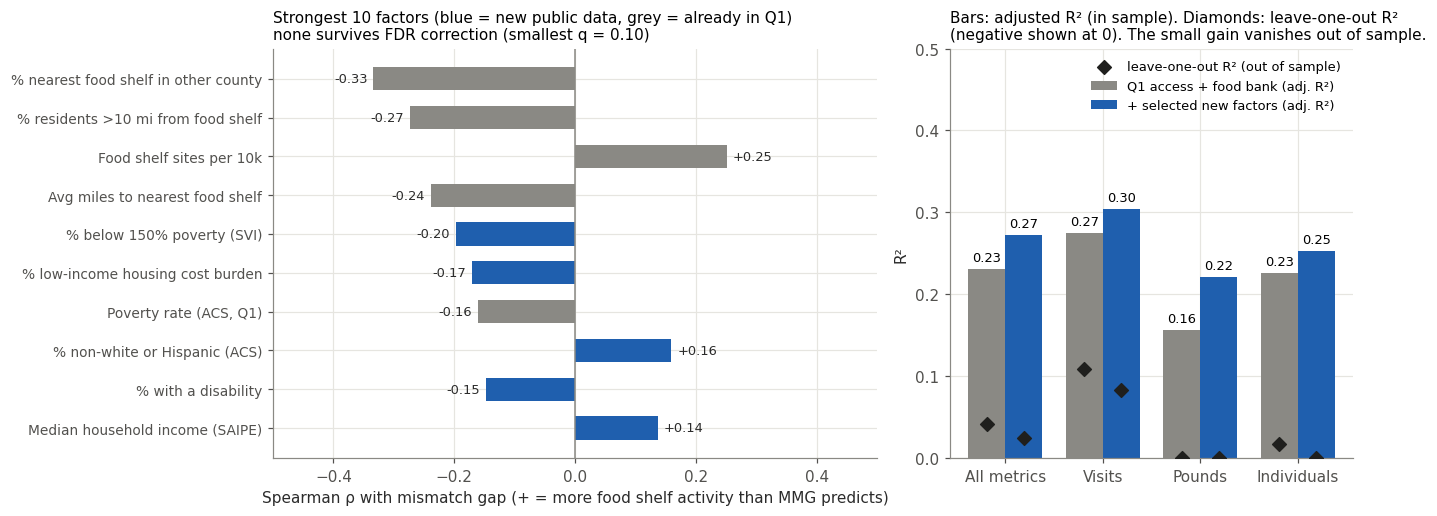

In [26]:
# Slide chart: the 10 strongest factors (all-metrics gap), new vs existing, with FDR status
s = tests[(tests["metric"] == "All metrics") & (tests["test"] == "spearman") & (tests["factor"] != "visits_per_site_month")]
s = s.reindex(s["rho"].abs().sort_values(ascending=False).index).head(10).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
cols = ["#1f5fae" if new else "#8a8984" for new in s["is_new"]]   # blue = new (06a or ACS)
ax.barh(range(len(s)), s["rho"], color=cols, height=0.6)
for i, (r, q) in enumerate(zip(s["rho"], s["q_fdr"])):
    ax.text(r + (0.01 if r > 0 else -0.01), i, f"{r:+.2f}" + (" (FDR ✓)" if q < ALPHA else ""),
            va="center", ha="left" if r > 0 else "right", fontsize=8.5, color="#2b2b2b")
ax.set_yticks(range(len(s))); ax.set_yticklabels(s["label"], fontsize=9)
ax.axvline(0, color="#8a8984", lw=1); ax.set_xlim(-0.5, 0.5)
ax.set_xlabel("Spearman ρ with mismatch gap (+ = more food shelf activity than MMG predicts)")
ax.set_title(f"Strongest 10 factors (blue = new public data, grey = already in Q1)" + chr(10) + f"none survives FDR correction (smallest q = {s['q_fdr'].min():.2f})", loc="left", fontsize=10)
ax.set_axisbelow(True)
ax = axes[1]
x = np.arange(4); w = 0.38
ax.bar(x - w / 2, nested["adj R² base"], w, color="#8a8984", label="Q1 access + food bank (adj. R²)")
ax.bar(x + w / 2, nested["adj R² +new"], w, color="#1f5fae", label="+ selected new factors (adj. R²)")
for i in range(4):
    ax.text(i - w / 2, nested["adj R² base"].iloc[i] + 0.01, f"{nested['adj R² base'].iloc[i]:.2f}", ha="center", fontsize=8.5)
    ax.text(i + w / 2, nested["adj R² +new"].iloc[i] + 0.01, f"{nested['adj R² +new'].iloc[i]:.2f}", ha="center", fontsize=8.5)
ax.scatter(x - w / 2, nested["LOO R² base"].clip(lower=0), marker="D", s=40, color="#1f1f1d", zorder=3, label="leave-one-out R² (out of sample)")
ax.scatter(x + w / 2, nested["LOO R² +new"].clip(lower=0), marker="D", s=40, color="#1f1f1d", zorder=3)
ax.set_axisbelow(True)
ax.set_xticks(x); ax.set_xticklabels(nested.index); ax.set_ylabel("R²"); ax.set_ylim(0, 0.5)
ax.set_title("Bars: adjusted R² (in sample). Diamonds: leave-one-out R²" + chr(10) + "(negative shown at 0). The small gain vanishes out of sample.", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
fig.tight_layout()
fig.savefig(OUT / "q1b_slide.png")
plt.show()

**Three sentences for the slide**

1. We tested 44 new public county factors (unemployment, SAIPE poverty and income, grocery stores, USDA food access, broadband, language, social ties, tribal areas, age, disability, and from the Census API the SNAP gap, housing cost burden, foreign-born and seniors living alone; later also MN DEED cost of living, USDA SNAP retailer access and MN WIC participation) against the Q1 mismatch, and **none survives correction for multiple testing**. Hardship can't explain deviations from Feeding America's estimate because MMG already builds hardship into that estimate.
2. **The strongest explanation is still access across county lines:** where more residents' nearest food shelf is in another county, the county records less activity than expected (ρ ≈ −0.33). It ranks first in the correlations, the regression and a random forest, and new factors add no out-of-sample explanatory power.
3. The three metrics share this explanation. The *pounds*-specific part tracks the **food bank network** (Channel One counties give less food per visit), and the *individuals*-specific part tracks **household size**. Children show the same pattern as everyone (child gap vs. all-ages gap ρ = 0.96).

Charts: `outputs/q1b/q1b_slide.png` (main), `outputs/q1b/q1b_factor_heatmap.png` (backup / appendix), `outputs/q1b/q1b_children.png` (children).

## 16. Children: child food insecurity vs. children served

The same question as Q1, for children only. **Need:** Map the Meal Gap `fi_children` (food-insecure children) and `child_fi_rate`. **Activity:** the food shelf `children` count (children in served households, summed over the year, so a child who comes every month counts 12 times, same as `individuals`). **Child population:** ACS `pop_under18_acs` (B09001, 5-year window ending that year, from `06b`).

Steps (2022–2024, 86 counties with a food shelf):
1. Spearman of **counts** (children served vs. food-insecure children) and of **rates** (children served per child resident vs. child FI rate).
2. Method A in miniature: per year, regress log2(children served) on log2(food-insecure children); the **child gap** is the distance from the line (−1 = half the expected, +1 = double); average over the 3 years.
3. Compare with the all-ages **individuals** gap: if the child gap just repeats it, children follow the same access/network pattern; counties where the two disagree are child-specific.
4. Who is served vs. who is food insecure: children's share of individuals served vs. children's share of food-insecure people.

**Seniors:** Map the Meal Gap publishes **no county senior food-insecurity estimate** (Feeding America's *State of Senior Hunger* is state-level only), so a senior version of this check isn't possible; we only report the seniors' share of individuals served.

In [27]:
fs_c = fs.groupby(["fips", "year"])[["individuals", "children", "seniors"]].sum(min_count=1).reset_index()
kid = (mmg[["fips", "county", "year", "fi_children", "child_fi_rate", "fi_persons"]]
       .merge(fs_c, on=["fips", "year"], how="left")
       .merge(fy[["fips", "year", "pop_under18_acs", "pop_pep"]], on=["fips", "year"], how="left"))
kid = kid[kid["fips"].isin(scored["fips"])].dropna(subset=["children"])
kid["children_per_child"] = kid["children"] / kid["pop_under18_acs"]
for year, g in kid.groupby("year"):
    x = np.log2(g["fi_children"]); y = np.log2(g["children"])
    b, a = np.polyfit(x, y, 1)
    kid.loc[g.index, "child_gap"] = y - (a + b * x)
kc = kid.groupby(["fips", "county"]).agg(fi_children=("fi_children", "mean"), children=("children", "mean"),
                                          child_fi_rate=("child_fi_rate", "mean"), children_per_child=("children_per_child", "mean"),
                                          child_gap=("child_gap", "mean")).reset_index()
kc = kc.merge(scored[["fips", "individuals_mean_gap", "mean_gap_all", "pct_nearest_other_county", "main_food_bank"]], on="fips")
r_cnt = stats.spearmanr(kc["children"], kc["fi_children"]); r_rate = stats.spearmanr(kc["children_per_child"], kc["child_fi_rate"])
print(f"Counts: Spearman(children served, food-insecure children) = {r_cnt[0]:.2f} (p = {r_cnt[1]:.1e})")
print(f"Rates:  Spearman(children served per child, child FI rate) = {r_rate[0]:.2f} (p = {r_rate[1]:.2f})")
ri = stats.spearmanr(kc["child_gap"], kc["individuals_mean_gap"])
print(f"Child gap vs all-ages individuals gap: Spearman = {ri[0]:.2f}; child gap vs % nearest shelf in other county: "
      f"{stats.spearmanr(kc['child_gap'], kc['pct_nearest_other_county'])[0]:.2f} "
      f"(all-ages: {stats.spearmanr(kc['individuals_mean_gap'], kc['pct_nearest_other_county'])[0]:.2f})")
kc["child_minus_indiv"] = kc["child_gap"] - kc["individuals_mean_gap"]
print("Per year, children served per food-insecure child (state, sum of counties):",
      kid.groupby("year").apply(lambda g: round(g["children"].sum() / g["fi_children"].sum(), 1), include_groups=False).to_dict())
share = kid.groupby("year").apply(lambda g: pd.Series({"children % of individuals served": 100 * g["children"].sum() / g["individuals"].sum(),
                                                       "children % of food-insecure people (MMG)": 100 * g["fi_children"].sum() / g["fi_persons"].sum(),
                                                       "seniors % of individuals served": 100 * g["seniors"].sum() / g["individuals"].sum()}),
                                  include_groups=False).round(1)
display(share)
kc["children_share_served"] = kc["fips"].map(kid.groupby("fips").apply(lambda g: g["children"].sum() / g["individuals"].sum(), include_groups=False))
kc["children_share_fi"] = kc["fips"].map(kid.groupby("fips").apply(lambda g: g["fi_children"].sum() / g["fi_persons"].sum(), include_groups=False))
print("Spearman(children's share served, children's share of FI) across counties:",
      round(kc["children_share_served"].corr(kc["children_share_fi"], method="spearman"), 2))
cols_k = ["county", "fi_children", "children", "child_gap", "individuals_mean_gap", "child_minus_indiv"]
print("\nFar FEWER children served than child FI predicts (child gap < -1, i.e. under half):")
display(kc[kc["child_gap"] < -1].sort_values("child_gap")[cols_k].round(2))
print("Far MORE (child gap > +1, over double):")
display(kc[kc["child_gap"] > 1].sort_values("child_gap", ascending=False)[cols_k].round(2))
print("Where children differ most from the all-ages pattern (|child gap - individuals gap| largest):")
kc.reindex(kc["child_minus_indiv"].abs().sort_values(ascending=False).index).head(6)[cols_k].round(2)

Counts: Spearman(children served, food-insecure children) = 0.90 (p = 1.9e-31)
Rates:  Spearman(children served per child, child FI rate) = 0.11 (p = 0.29)
Child gap vs all-ages individuals gap: Spearman = 0.96; child gap vs % nearest shelf in other county: -0.35 (all-ages: -0.33)
Per year, children served per food-insecure child (state, sum of counties): {2022: 11.2, 2023: 14.6, 2024: 15.9}


,children % of individuals served,children % of food-insecure people (MMG),seniors % of individuals served
year,,,
2022,35.8,35.4,13.1
2023,35.9,32.2,11.5
2024,36.3,32.3,10.9


Spearman(children's share served, children's share of FI) across counties: 0.51

Far FEWER children served than child FI predicts (child gap < -1, i.e. under half):


,county,fi_children,children,child_gap,individuals_mean_gap,child_minus_indiv
40,Lincoln,183.33,248.33,-1.72,-0.49,-1.23
60,Pope,316.67,446.67,-1.68,-1.81,0.13
4,Benton,1706.67,4183.00,-1.65,-1.28,-0.37
36,Lac qui Parle,206.67,276.67,-1.64,-1.55,-0.09
51,Nicollet,1040.00,2575.67,-1.38,-1.70,0.32
69,Scott,3890.00,14044.67,-1.33,-1.15,-0.17
25,Grant,263.33,505.00,-1.23,-0.77,-0.46
7,Brown,740.00,2008.00,-1.10,-1.14,0.04
8,Carlton,1343.33,4231.67,-1.08,-0.75,-0.32
76,Todd,1086.67,3484.33,-1.02,-0.89,-0.13


Far MORE (child gap > +1, over double):


,county,fi_children,children,child_gap,individuals_mean_gap,child_minus_indiv
73,Steele,1196.67,44602.00,2.41,2.26,0.16
81,Washington,6506.67,329216.00,2.28,2.12,0.16
65,Rice,2156.67,75358.67,2.10,1.92,0.19
64,Renville,570.00,10263.67,1.77,1.75,0.02
15,Cook,160.00,1850.33,1.64,1.26,0.38
6,Blue Earth,2150.00,47381.33,1.53,0.95,0.58
31,Jackson,340.00,3992.67,1.31,1.01,0.30
78,Wabasha,593.33,7973.00,1.30,1.00,0.30
82,Watonwan,466.67,5911.33,1.25,1.01,0.24
58,Pipestone,400.00,4737.67,1.23,1.19,0.04


Where children differ most from the all-ages pattern (|child gap - individuals gap| largest):


,county,fi_children,children,child_gap,individuals_mean_gap,child_minus_indiv
40,Lincoln,183.33,248.33,-1.72,-0.49,-1.23
6,Blue Earth,2150.00,47381.33,1.53,0.95,0.58
74,Stevens,310.00,2058.67,0.54,0.07,0.46
25,Grant,263.33,505.00,-1.23,-0.77,-0.46
12,Chisago,1563.33,6551.67,-0.72,-0.27,-0.45
83,Winona,1213.33,7039.33,-0.18,-0.57,0.39


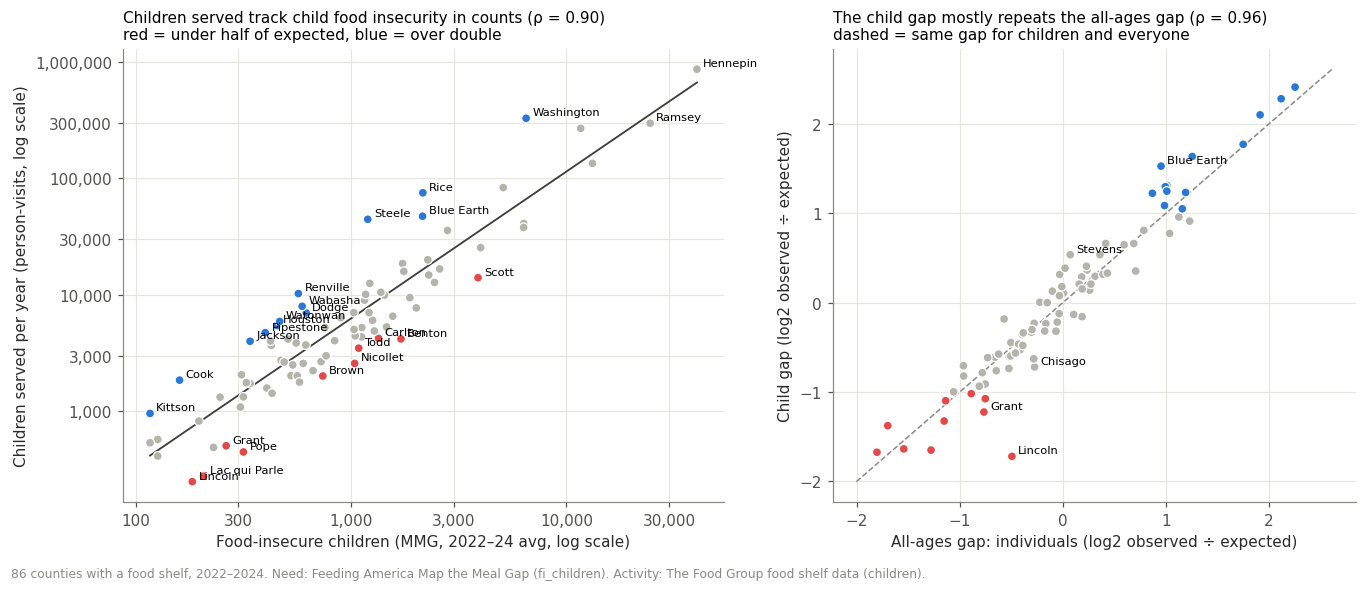

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
x, y = np.log2(kc["fi_children"]), np.log2(kc["children"])
b, a = np.polyfit(x, y, 1)
col = np.where(kc["child_gap"] < -1, "#e34948", np.where(kc["child_gap"] > 1, "#2a78d6", "#b5b4ac"))
ax.scatter(x, y, c=col, s=34, edgecolor="white", linewidth=0.8, zorder=3)
xx = np.linspace(x.min(), x.max(), 50); ax.plot(xx, a + b * xx, color="#3d3d3a", lw=1.2)
for _, r in kc[(kc["child_gap"].abs() > 1) | kc["county"].isin(["Hennepin", "Ramsey"])].iterrows():
    ax.annotate(r["county"], (np.log2(r["fi_children"]), np.log2(r["children"])), xytext=(4, 2), textcoords="offset points", fontsize=7.5)
tk = [100, 300, 1000, 3000, 10000, 30000]
ax.set_xticks(np.log2(tk)); ax.set_xticklabels([f"{v:,}" for v in tk])
tk2 = [1000, 3000, 10000, 30000, 100000, 300000, 1000000]
ax.set_yticks(np.log2(tk2)); ax.set_yticklabels([f"{v:,}" for v in tk2])
ax.set_xlabel("Food-insecure children (MMG, 2022–24 avg, log scale)"); ax.set_ylabel("Children served per year (person-visits, log scale)")
ax.set_title(f"Children served track child food insecurity in counts (ρ = {r_cnt[0]:.2f})\nred = under half of expected, blue = over double", loc="left", fontsize=10)
ax = axes[1]
ax.scatter(kc["individuals_mean_gap"], kc["child_gap"], c=col, s=34, edgecolor="white", linewidth=0.8, zorder=3)
lim = [min(kc["individuals_mean_gap"].min(), kc["child_gap"].min()) - 0.2, max(kc["individuals_mean_gap"].max(), kc["child_gap"].max()) + 0.2]
ax.plot(lim, lim, color="#8a8984", ls="--", lw=1)
for _, r in kc.reindex(kc["child_minus_indiv"].abs().sort_values(ascending=False).index).head(5).iterrows():
    ax.annotate(r["county"], (r["individuals_mean_gap"], r["child_gap"]), xytext=(4, 2), textcoords="offset points", fontsize=7.5)
ax.set_xlabel("All-ages gap: individuals (log2 observed ÷ expected)"); ax.set_ylabel("Child gap (log2 observed ÷ expected)")
ax.set_title(f"The child gap mostly repeats the all-ages gap (ρ = {ri[0]:.2f})\ndashed = same gap for children and everyone", loc="left", fontsize=10)
fig.text(0.01, -0.02, "86 counties with a food shelf, 2022–2024. Need: Feeding America Map the Meal Gap (fi_children). Activity: The Food Group food shelf data (children).",
         fontsize=8, color="#8a8984")
fig.tight_layout()
fig.savefig(OUT / "q1b_children.png"); plt.show()

**Result (children)**
- **Counts line up, rates don't** (same as all ages in Q1): counties with more food-insecure children serve more children (ρ = 0.90), but children served **per child resident** barely follows the child FI **rate** (ρ = 0.11, p = 0.29).
- **Children are not under-served relative to everyone else.** Statewide, children are 36% of individuals served and 32–35% of food-insecure people (MMG). Across counties the two shares move together (ρ = 0.51). Children served per food-insecure child rose from 11 (2022) to 16 (2024) person-visits a year.
- **The child gap almost copies the all-ages gap** (ρ = 0.96) and has the same cross-county link (ρ = −0.35 with % nearest food shelf in another county vs. −0.33 for all ages). The same counties are low: Pope, Benton, Lac qui Parle, Nicollet, Scott, Grant, Brown, Carlton, Todd (under half of the children expected), and the same hubs are high (Steele, Washington, Rice, Renville, Blue Earth: over double).
- **The one child-specific outlier is Lincoln**: children served are under a third of expected (gap −1.72) while all ages are only modestly low (−0.49). Blue Earth goes the other way (children +1.53 vs. +0.95). Lincoln is a small county (≈ 180 food-insecure children), so this is worth a question to the local food shelf, not a statewide pattern.
- **Seniors:** no county senior food-insecurity estimate exists in MMG, so no senior version. For context only: seniors are 11–13% of individuals served (falling from 13.1% in 2022 to 10.9% in 2024).
- **Caveat:** `children` counts children in served households each month (person-visits), and some food shelves may record household composition loosely. Treat the child results as a consistency check on Q1, not a separate finding.